## Hypothesis and Contributions 
 
### Hypothesis 1: It is possible to port NUNO to NVIDIA PhysicsNeMo



#### Objective 1: Datasets
- Create point list by randomly sampling cartesian coordinates
- Interpolate (using GPU-accelerated bi-linear sampling) existing Darcy2D data
- Save this dataset as hdf5 file   
- Seperate between training and validation datasets

Expected Result: Randomly sampled list of points for different input and output channels 

In [1]:
import h5py
import numpy as np
import os

def inspect_nuno_h5(file_path):
    
    with h5py.File(file_path, 'r') as f:
        print("--- A) Header & Dataset Information ---")
        print(f"{'Dataset Name':<15} | {'Shape':<20} | {'Dtype':<10} | {'Chunks'}")
        print("-" * 65)
        
        for key in f.keys():
            dset = f[key]
            if hasattr(dset, 'shape'):
                print(f"{key:<15} | {str(dset.shape):<20} | {str(dset.dtype):<10} | {str(dset.chunks)}")
        
        print("\n--- B) Sample Values (First 5 entries) ---")
        
        # 1. Coordinates (Fixed for all samples)
        if 'coordinates' in f:
            coords = f['coordinates'][:]
            print(f"\n Coordinates (Fixed Geometry) [Shape: {coords.shape}]")
            print(f"   First 5 points:\n{coords[:5]}")
            print(f"   Range: X[{coords[:,0].min():.2f}, {coords[:,0].max():.2f}], "
                  f"Y[{coords[:,1].min():.2f}, {coords[:,1].max():.2f}]")

        # 2. Permeability (Input)
        if 'permeability' in f and f['permeability'].shape[0] > 0:
            perm = f['permeability'][0]  # Get first sample
            print(f"\n Permeability (Sample 0) [Shape: {perm.shape}]")
            print(f"   First 5 values:\n{perm[:5].flatten()}")
            print(f"   Stats: Min={perm.min():.4f}, Max={perm.max():.4f}, Mean={perm.mean():.4f}")

        # 3. Pressure (Target)
        if 'pressure' in f and f['pressure'].shape[0] > 0:
            press = f['pressure'][0]  # Get first sample
            print(f"\n Pressure (Sample 0) [Shape: {press.shape}]")
            print(f"   First 5 values:\n{press[:5].flatten()}")
            print(f"   Stats: Min={press.min():.4f}, Max={press.max():.4f}, Mean={press.mean():.4f}")

# --- USAGE ---
# Update this path to point to your specific generated file
file_path = "E:\\Development\\thesis\\physicsnemo\\examples\\cfd\\darcy_nuno\\data\\train\\darcy_nuno_train_000.h5" 

inspect_nuno_h5(file_path)


--- A) Header & Dataset Information ---
Dataset Name    | Shape                | Dtype      | Chunks
-----------------------------------------------------------------
coordinates     | (1024, 2)            | float32    | None
permeability    | (1000, 1024, 1)      | float32    | (1, 1024, 1)
pressure        | (1000, 1024, 1)      | float32    | (1, 1024, 1)

--- B) Sample Values (First 5 entries) ---

 Coordinates (Fixed Geometry) [Shape: (1024, 2)]
   First 5 points:
[[ 0.22591972 -0.9798823 ]
 [-0.20317262 -0.9193832 ]
 [-0.6874665  -0.03505385]
 [ 0.4724946  -0.18803608]
 [ 0.03779924 -0.4265778 ]]
   Range: X[-1.00, 1.00], Y[-1.00, 1.00]

 Permeability (Sample 0) [Shape: (1024, 1)]
   First 5 values:
[2.  0.5 0.5 2.  0.5]
   Stats: Min=0.2850, Max=2.0000, Mean=1.1012

 Pressure (Sample 0) [Shape: (1024, 1)]
   First 5 values:
[0.00559361 0.01951539 0.06349159 0.07883428 0.09132688]
   Stats: Min=0.0003, Max=0.1047, Mean=0.0494


#### Objective 2: Model
- Abstract Liu et. al (2023) code to work as a standalone "model" in physicsnemo
- Use existing FNO implementations to conform to repository 
- Reuse KD-Tree from Liu et. al but wrap with additional classes to match physicsnemo standards
- Add Tests to test library within phyiscsnemo

Expected Result: nuno.py, a model file in physicsnemo which fits into existing structures and workflows and utilizes CUDA, passes all 55 tests

In [2]:
from physicsnemo.models.fno.nuno import NUNO 
print(NUNO(1,2))

NUNO(
  (activation_fn): GELU(approximate='none')
  (spec_encoder): FNO2DEncoder(
    (activation_fn): GELU(approximate='none')
    (lift_network): Sequential(
      (0): Conv2dFCLayer(
        (activation_fn): Identity()
        (conv): Conv2d(10, 16, kernel_size=(1, 1), stride=(1, 1))
      )
      (1): GELU(approximate='none')
      (2): Conv2dFCLayer(
        (activation_fn): Identity()
        (conv): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
      )
    )
    (spconv_layers): ModuleList(
      (0-3): 4 x SpectralConv2d()
    )
    (conv_layers): ModuleList(
      (0-3): 4 x Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1))
    )
  )
  (decoder_net): FullyConnected(
    (layers): ModuleList(
      (0): FCLayer(
        (activation_fn): SiLU()
        (linear): Linear(in_features=32, out_features=32, bias=True)
      )
    )
    (final_layer): FCLayer(
      (activation_fn): Identity()
      (linear): Linear(in_features=32, out_features=16, bias=True)
    )
  )
)


#### Objective 3: Training run
- Train NUNO on non-uniform dataset with PhysicsNeMo decorators and Adam Optimizer
- Ensure domain decomposition is functioning as expected
- Ensure validation loss is decreasing over time
- Visualize results

Expected Result: Decreasing valdiation loss, clear K-D tree with multiple sub-domains

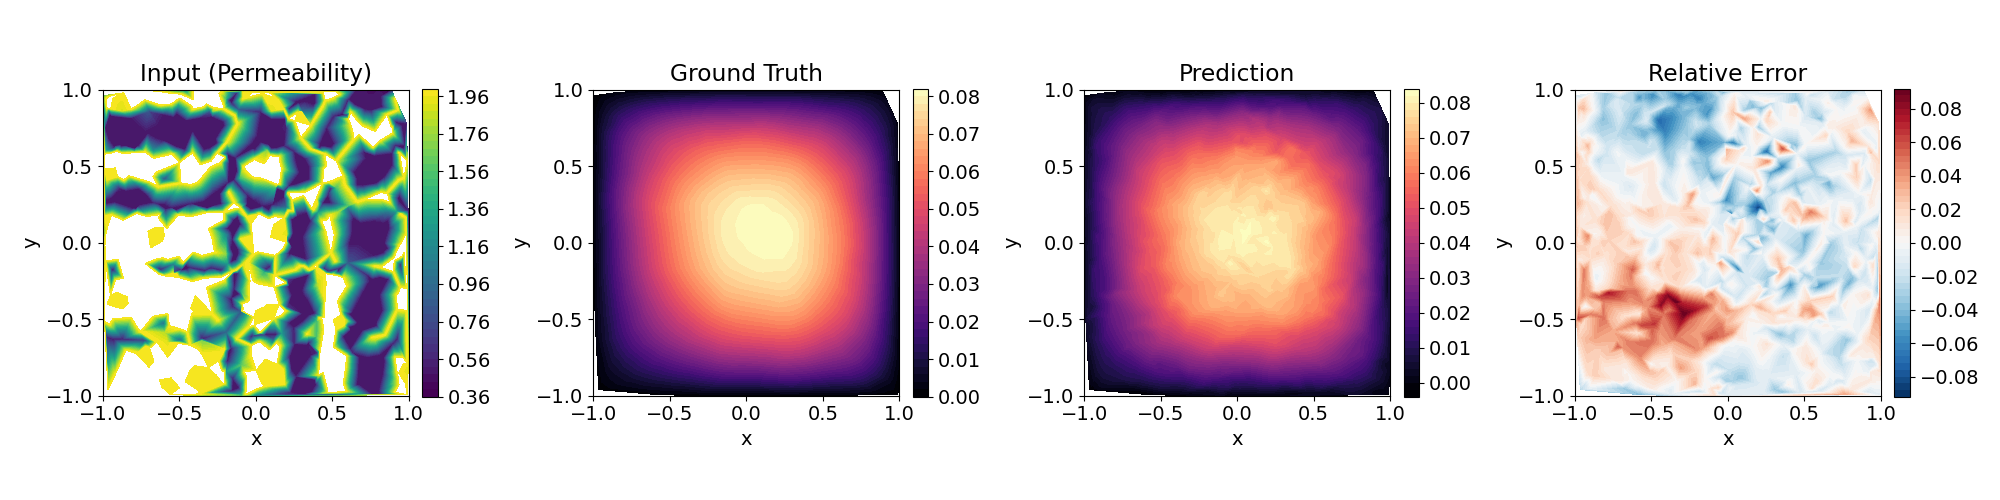

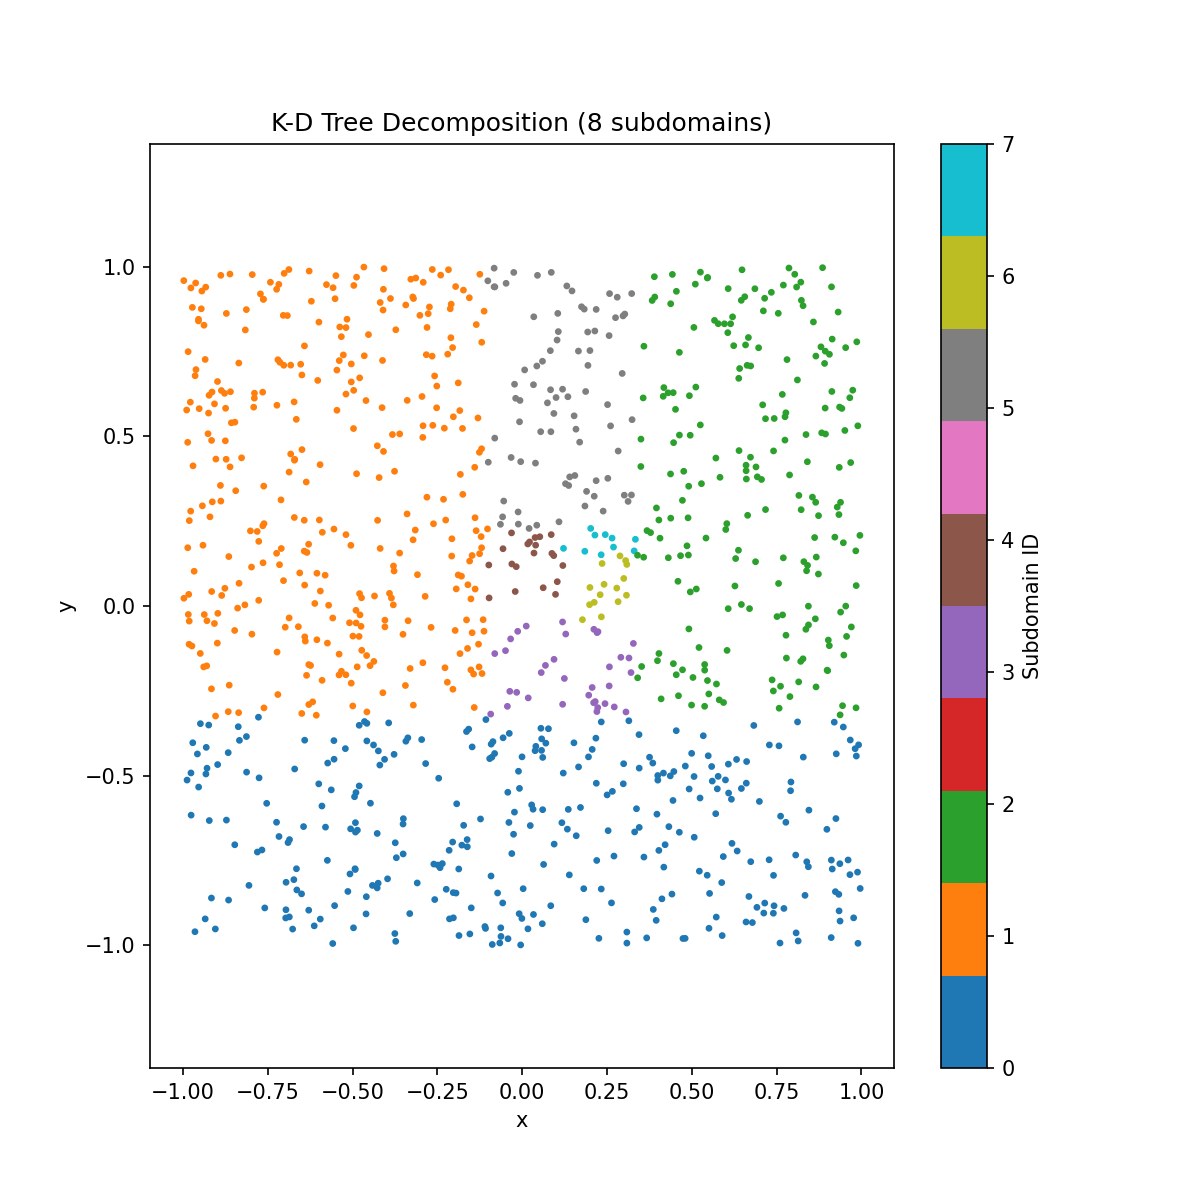

In [4]:
from IPython.display import Image, display

base_path = 'E:\\Development\\thesis\\physicsnemo\\images\\'

listOfImageNames = ['5070ti_nuno_validation_step_032.png',
                    'subdomain_visualization.png']

## TODO: Write script for subdomain visualization

for imageName in listOfImageNames:
    display(Image(filename= base_path + imageName))


### Hypothesis 2: NUNO performs at least better than globally interpolated FNO   
- This hypothesis not only tests if our implementation is functional but also verifies the authors claims for NUNO
- Constraints: NUNO is allowed to use more space in memory for KD-Tree;


#### Objective 0: NUNO scales with train time

|

In [24]:
log_data_4096 = """
[2026-01-30 20:32:43,708][nuno_darcy_live_sampling][INFO] - [94mInitializing training sampler: random[0m
[2026-01-30 20:32:43,826][nuno_darcy_live_sampling][INFO] - [94mGenerated fixed point cloud geometry: 4096 points[0m
[2026-01-30 20:32:43,826][nuno_darcy_live_sampling][INFO] - [94mLoading uniform grid training data...[0m
[2026-01-30 20:32:43,832][nuno_darcy_live_sampling][INFO] - [94mLoading uniform grid validation data...[0m
[2026-01-30 20:32:43,839][nuno_darcy_live_sampling][INFO] - [94mCreating NUNO model...[0m
[2026-01-30 20:32:43,895][nuno_darcy_live_sampling][INFO] - [94mSetting up NUNO domain decomposition...[0m
[2026-01-30 20:32:44,615][visualize][INFO] - [94mSaved subdomain visualization to 'subdomain_visualization.png'[0m
[2026-01-30 20:32:44,630][nuno_darcy_live_sampling][INFO] - [94mModel parameters: 2,365,512[0m
[2026-01-30 20:32:44,630][nuno_darcy_live_sampling][INFO] - [94mTraining on point clouds of size 4096[0m
[2026-01-30 20:32:44,630][nuno_darcy_live_sampling][INFO] - [94mMax grid size in subdomains: (79, 39)[0m
[2026-01-30 20:32:44,932][checkpoint][INFO] - [92mLoaded model state dictionary E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.40.mdlus to device cuda:0[0m
[2026-01-30 20:32:45,002][checkpoint][INFO] - [92mLoaded checkpoint file E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.40.pt to device cuda:0[0m
[2026-01-30 20:32:45,002][checkpoint][INFO] - [92mLoaded optimizer state dictionary[0m
[2026-01-30 20:32:45,002][checkpoint][INFO] - [92mLoaded scheduler state dictionary[0m
[2026-01-30 20:32:45,002][checkpoint][INFO] - [92mLoaded static capture state dictionary[0m
[2026-01-30 20:32:45,003][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support CUDA graphs, turning off[0m
[2026-01-30 20:32:45,003][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support AMP on GPUs, turning off[0m
[2026-01-30 20:32:45,003][nuno_darcy_live_sampling][INFO] - [94mLoaded grad scaler state dictionary scaler_0.[0m
[2026-01-30 20:32:45,006][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support CUDA graphs, turning off[0m
[2026-01-30 20:32:45,006][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support AMP on GPUs, turning off[0m
[2026-01-30 20:32:45,007][nuno_darcy_live_sampling][INFO] - [94mLoaded grad scaler state dictionary scaler_1.[0m
[2026-01-30 20:32:45,007][nuno_darcy_live_sampling][WARNING] - [93mResuming training from pseudo epoch 41.[0m
[2026-01-30 20:33:38,688][train][INFO] - [94mEpoch 41 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  1.609e+03, loss =  6.036e-01[0m
[2026-01-30 20:33:38,688][train][INFO] - [94mEpoch Execution Time:  5.368e+01s, Time/Iter:  1.342e+04ms[0m
[2026-01-30 20:34:31,794][train][INFO] - [94mEpoch 42 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.827e+02, loss =  6.443e-01[0m
[2026-01-30 20:34:31,794][train][INFO] - [94mEpoch Execution Time:  5.311e+01s, Time/Iter:  1.328e+04ms[0m
[2026-01-30 20:35:26,737][train][INFO] - [94mEpoch 43 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.024e+02, loss =  1.358e+00[0m
[2026-01-30 20:35:26,737][train][INFO] - [94mEpoch Execution Time:  5.494e+01s, Time/Iter:  1.374e+04ms[0m
[2026-01-30 20:36:20,303][train][INFO] - [94mEpoch 44 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.278e+02, loss =  4.243e-01[0m
[2026-01-30 20:36:20,303][train][INFO] - [94mEpoch Execution Time:  5.357e+01s, Time/Iter:  1.339e+04ms[0m
[2026-01-30 20:36:41,833][nuno_darcy_live_sampling][INFO] - [94mEpoch 44: Validation loss = 0.604716[0m
[2026-01-30 20:36:41,833][valid][INFO] - [94mEpoch 44 Metrics: Validation Loss =  6.047e-01[0m
[2026-01-30 20:36:41,834][valid][INFO] - [94mEpoch Execution Time:  2.153e+01s, Time/Iter:  2.153e+04ms[0m
[2026-01-30 20:37:34,898][train][INFO] - [94mEpoch 45 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.128e+02, loss =  6.306e-01[0m
[2026-01-30 20:37:34,899][train][INFO] - [94mEpoch Execution Time:  5.306e+01s, Time/Iter:  1.327e+04ms[0m
[2026-01-30 20:38:27,256][train][INFO] - [94mEpoch 46 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.303e+02, loss =  9.489e-01[0m
[2026-01-30 20:38:27,256][train][INFO] - [94mEpoch Execution Time:  5.236e+01s, Time/Iter:  1.309e+04ms[0m
[2026-01-30 20:39:22,186][train][INFO] - [94mEpoch 47 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.705e+02, loss =  1.285e+00[0m
[2026-01-30 20:39:22,187][train][INFO] - [94mEpoch Execution Time:  5.493e+01s, Time/Iter:  1.373e+04ms[0m
[2026-01-30 20:40:16,343][train][INFO] - [94mEpoch 48 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.119e+02, loss =  1.015e+00[0m
[2026-01-30 20:40:16,344][train][INFO] - [94mEpoch Execution Time:  5.416e+01s, Time/Iter:  1.354e+04ms[0m
[2026-01-30 20:40:16,410][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.48.mdlus[0m
[2026-01-30 20:40:16,431][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.48.pt[0m
[2026-01-30 20:40:16,431][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 48[0m
[2026-01-30 20:40:38,179][nuno_darcy_live_sampling][INFO] - [94mEpoch 48: Validation loss = 0.564599[0m
[2026-01-30 20:40:38,179][valid][INFO] - [94mEpoch 48 Metrics: Validation Loss =  5.646e-01[0m
[2026-01-30 20:40:38,180][valid][INFO] - [94mEpoch Execution Time:  2.175e+01s, Time/Iter:  2.175e+04ms[0m
[2026-01-30 20:41:31,409][train][INFO] - [94mEpoch 49 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.880e+02, loss =  3.407e-01[0m
[2026-01-30 20:41:31,410][train][INFO] - [94mEpoch Execution Time:  5.323e+01s, Time/Iter:  1.331e+04ms[0m
[2026-01-30 20:42:23,751][train][INFO] - [94mEpoch 50 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.636e+02, loss =  8.896e-01[0m
[2026-01-30 20:42:23,751][train][INFO] - [94mEpoch Execution Time:  5.234e+01s, Time/Iter:  1.309e+04ms[0m
[2026-01-30 20:42:23,751][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.61e-04[0m
[2026-01-30 20:43:16,480][train][INFO] - [94mEpoch 51 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.648e+02, loss =  3.153e-01[0m
[2026-01-30 20:43:16,481][train][INFO] - [94mEpoch Execution Time:  5.273e+01s, Time/Iter:  1.318e+04ms[0m
[2026-01-30 20:44:08,867][train][INFO] - [94mEpoch 52 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.940e+02, loss =  1.167e-01[0m
[2026-01-30 20:44:08,868][train][INFO] - [94mEpoch Execution Time:  5.239e+01s, Time/Iter:  1.310e+04ms[0m
[2026-01-30 20:44:30,244][nuno_darcy_live_sampling][INFO] - [94mEpoch 52: Validation loss = 0.511138[0m
[2026-01-30 20:44:30,244][valid][INFO] - [94mEpoch 52 Metrics: Validation Loss =  5.111e-01[0m
[2026-01-30 20:44:30,244][valid][INFO] - [94mEpoch Execution Time:  2.138e+01s, Time/Iter:  2.138e+04ms[0m
[2026-01-30 20:45:22,452][train][INFO] - [94mEpoch 53 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.428e+02, loss =  8.234e-01[0m
[2026-01-30 20:45:22,452][train][INFO] - [94mEpoch Execution Time:  5.221e+01s, Time/Iter:  1.305e+04ms[0m
[2026-01-30 20:46:14,970][train][INFO] - [94mEpoch 54 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.206e+02, loss =  2.841e-01[0m
[2026-01-30 20:46:14,970][train][INFO] - [94mEpoch Execution Time:  5.252e+01s, Time/Iter:  1.313e+04ms[0m
[2026-01-30 20:47:09,163][train][INFO] - [94mEpoch 55 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.656e+02, loss =  3.682e-01[0m
[2026-01-30 20:47:09,163][train][INFO] - [94mEpoch Execution Time:  5.419e+01s, Time/Iter:  1.355e+04ms[0m
[2026-01-30 20:48:01,611][train][INFO] - [94mEpoch 56 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.533e+02, loss =  4.615e-01[0m
[2026-01-30 20:48:01,611][train][INFO] - [94mEpoch Execution Time:  5.245e+01s, Time/Iter:  1.311e+04ms[0m
[2026-01-30 20:48:01,661][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.56.mdlus[0m
[2026-01-30 20:48:01,683][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.56.pt[0m
[2026-01-30 20:48:01,683][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 56[0m
[2026-01-30 20:48:23,665][nuno_darcy_live_sampling][INFO] - [94mEpoch 56: Validation loss = 0.501727[0m
[2026-01-30 20:48:23,665][valid][INFO] - [94mEpoch 56 Metrics: Validation Loss =  5.017e-01[0m
[2026-01-30 20:48:23,665][valid][INFO] - [94mEpoch Execution Time:  2.198e+01s, Time/Iter:  2.198e+04ms[0m
[2026-01-30 20:49:16,194][train][INFO] - [94mEpoch 57 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.471e+02, loss =  9.163e-01[0m
[2026-01-30 20:49:16,195][train][INFO] - [94mEpoch Execution Time:  5.253e+01s, Time/Iter:  1.313e+04ms[0m
[2026-01-30 20:50:08,826][train][INFO] - [94mEpoch 58 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  8.150e+02, loss =  9.127e-01[0m
[2026-01-30 20:50:08,826][train][INFO] - [94mEpoch Execution Time:  5.263e+01s, Time/Iter:  1.316e+04ms[0m
[2026-01-30 20:51:01,636][train][INFO] - [94mEpoch 59 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  8.094e+02, loss =  9.117e-01[0m
[2026-01-30 20:51:01,636][train][INFO] - [94mEpoch Execution Time:  5.281e+01s, Time/Iter:  1.320e+04ms[0m
[2026-01-30 20:51:53,975][train][INFO] - [94mEpoch 60 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.792e+02, loss =  3.046e-01[0m
[2026-01-30 20:51:53,975][train][INFO] - [94mEpoch Execution Time:  5.234e+01s, Time/Iter:  1.308e+04ms[0m
[2026-01-30 20:51:53,976][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.51e-04[0m
[2026-01-30 20:52:16,174][nuno_darcy_live_sampling][INFO] - [94mEpoch 60: Validation loss = 0.502519[0m
[2026-01-30 20:52:16,174][valid][INFO] - [94mEpoch 60 Metrics: Validation Loss =  5.025e-01[0m
[2026-01-30 20:52:16,174][valid][INFO] - [94mEpoch Execution Time:  2.220e+01s, Time/Iter:  2.220e+04ms[0m
[2026-01-30 20:53:11,229][train][INFO] - [94mEpoch 61 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.383e+02, loss =  1.556e+00[0m
[2026-01-30 20:53:11,235][train][INFO] - [94mEpoch Execution Time:  5.506e+01s, Time/Iter:  1.377e+04ms[0m
[2026-01-30 20:54:05,240][train][INFO] - [94mEpoch 62 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.984e+02, loss =  6.372e-01[0m
[2026-01-30 20:54:05,240][train][INFO] - [94mEpoch Execution Time:  5.401e+01s, Time/Iter:  1.350e+04ms[0m
[2026-01-30 20:54:56,558][train][INFO] - [94mEpoch 63 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  8.051e+02, loss =  3.164e-01[0m
[2026-01-30 20:54:56,558][train][INFO] - [94mEpoch Execution Time:  5.132e+01s, Time/Iter:  1.283e+04ms[0m
[2026-01-30 20:55:48,205][train][INFO] - [94mEpoch 64 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.911e+02, loss =  1.184e+00[0m
[2026-01-30 20:55:48,206][train][INFO] - [94mEpoch Execution Time:  5.165e+01s, Time/Iter:  1.291e+04ms[0m
[2026-01-30 20:55:48,268][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.64.mdlus[0m
[2026-01-30 20:55:48,287][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.64.pt[0m
[2026-01-30 20:55:48,288][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 64[0m
[2026-01-30 20:56:09,362][nuno_darcy_live_sampling][INFO] - [94mEpoch 64: Validation loss = 0.501687[0m
[2026-01-30 20:56:09,363][valid][INFO] - [94mEpoch 64 Metrics: Validation Loss =  5.017e-01[0m
[2026-01-30 20:56:09,363][valid][INFO] - [94mEpoch Execution Time:  2.107e+01s, Time/Iter:  2.107e+04ms[0m
[2026-01-30 20:57:01,438][train][INFO] - [94mEpoch 65 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.646e+02, loss =  1.241e+00[0m
[2026-01-30 20:57:01,439][train][INFO] - [94mEpoch Execution Time:  5.208e+01s, Time/Iter:  1.302e+04ms[0m
[2026-01-30 20:57:53,484][train][INFO] - [94mEpoch 66 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.167e+02, loss =  8.169e-01[0m
[2026-01-30 20:57:53,484][train][INFO] - [94mEpoch Execution Time:  5.205e+01s, Time/Iter:  1.301e+04ms[0m
[2026-01-30 20:58:45,501][train][INFO] - [94mEpoch 67 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.320e+02, loss =  3.294e-01[0m
[2026-01-30 20:58:45,501][train][INFO] - [94mEpoch Execution Time:  5.202e+01s, Time/Iter:  1.300e+04ms[0m
[2026-01-30 20:59:36,806][train][INFO] - [94mEpoch 68 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.611e+02, loss =  6.951e-01[0m
[2026-01-30 20:59:36,806][train][INFO] - [94mEpoch Execution Time:  5.130e+01s, Time/Iter:  1.283e+04ms[0m
[2026-01-30 20:59:57,904][nuno_darcy_live_sampling][INFO] - [94mEpoch 68: Validation loss = 0.501912[0m
[2026-01-30 20:59:57,905][valid][INFO] - [94mEpoch 68 Metrics: Validation Loss =  5.019e-01[0m
[2026-01-30 20:59:57,905][valid][INFO] - [94mEpoch Execution Time:  2.110e+01s, Time/Iter:  2.110e+04ms[0m
[2026-01-30 21:00:51,666][train][INFO] - [94mEpoch 69 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.674e+02, loss =  6.109e-01[0m
[2026-01-30 21:00:51,666][train][INFO] - [94mEpoch Execution Time:  5.376e+01s, Time/Iter:  1.344e+04ms[0m
[2026-01-30 21:01:43,945][train][INFO] - [94mEpoch 70 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.221e+02, loss =  8.202e-01[0m
[2026-01-30 21:01:43,946][train][INFO] - [94mEpoch Execution Time:  5.228e+01s, Time/Iter:  1.307e+04ms[0m
[2026-01-30 21:01:43,946][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.41e-04[0m
[2026-01-30 21:02:35,760][train][INFO] - [94mEpoch 71 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  8.088e+02, loss =  6.653e-01[0m
[2026-01-30 21:02:35,760][train][INFO] - [94mEpoch Execution Time:  5.181e+01s, Time/Iter:  1.295e+04ms[0m
[2026-01-30 21:03:27,522][train][INFO] - [94mEpoch 72 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  7.893e+02, loss =  7.503e-01[0m
[2026-01-30 21:03:27,522][train][INFO] - [94mEpoch Execution Time:  5.176e+01s, Time/Iter:  1.294e+04ms[0m
[2026-01-30 21:03:27,576][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.72.mdlus[0m
[2026-01-30 21:03:27,610][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.72.pt[0m
[2026-01-30 21:03:27,610][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 72[0m
[2026-01-30 21:03:48,676][nuno_darcy_live_sampling][INFO] - [94mEpoch 72: Validation loss = 0.496358[0m
[2026-01-30 21:03:48,677][valid][INFO] - [94mEpoch 72 Metrics: Validation Loss =  4.964e-01[0m
[2026-01-30 21:03:48,677][valid][INFO] - [94mEpoch Execution Time:  2.107e+01s, Time/Iter:  2.107e+04ms[0m
[2026-01-30 21:04:40,827][train][INFO] - [94mEpoch 73 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  7.371e+02, loss =  8.297e-01[0m
[2026-01-30 21:04:40,827][train][INFO] - [94mEpoch Execution Time:  5.215e+01s, Time/Iter:  1.304e+04ms[0m
[2026-01-30 21:05:33,056][train][INFO] - [94mEpoch 74 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  7.709e+02, loss =  1.009e+00[0m
[2026-01-30 21:05:33,056][train][INFO] - [94mEpoch Execution Time:  5.223e+01s, Time/Iter:  1.306e+04ms[0m
[2026-01-30 21:06:25,180][train][INFO] - [94mEpoch 75 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.752e+02, loss =  5.665e-01[0m
[2026-01-30 21:06:25,180][train][INFO] - [94mEpoch Execution Time:  5.212e+01s, Time/Iter:  1.303e+04ms[0m
[2026-01-30 21:07:18,209][train][INFO] - [94mEpoch 76 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.828e+02, loss =  2.227e-01[0m
[2026-01-30 21:07:18,209][train][INFO] - [94mEpoch Execution Time:  5.303e+01s, Time/Iter:  1.326e+04ms[0m
[2026-01-30 21:07:40,168][nuno_darcy_live_sampling][INFO] - [94mEpoch 76: Validation loss = 0.494205[0m
[2026-01-30 21:07:40,168][valid][INFO] - [94mEpoch 76 Metrics: Validation Loss =  4.942e-01[0m
[2026-01-30 21:07:40,168][valid][INFO] - [94mEpoch Execution Time:  2.196e+01s, Time/Iter:  2.196e+04ms[0m
[2026-01-30 21:08:31,840][train][INFO] - [94mEpoch 77 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.689e+02, loss =  9.534e-01[0m
[2026-01-30 21:08:31,840][train][INFO] - [94mEpoch Execution Time:  5.167e+01s, Time/Iter:  1.292e+04ms[0m
[2026-01-30 21:09:23,372][train][INFO] - [94mEpoch 78 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  7.254e+02, loss =  5.076e-01[0m
[2026-01-30 21:09:23,372][train][INFO] - [94mEpoch Execution Time:  5.153e+01s, Time/Iter:  1.288e+04ms[0m
[2026-01-30 21:10:15,170][train][INFO] - [94mEpoch 79 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  7.319e+02, loss =  1.834e-01[0m
[2026-01-30 21:10:15,171][train][INFO] - [94mEpoch Execution Time:  5.180e+01s, Time/Iter:  1.295e+04ms[0m
[2026-01-30 21:11:07,025][train][INFO] - [94mEpoch 80 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.745e+02, loss =  1.051e+00[0m
[2026-01-30 21:11:07,026][train][INFO] - [94mEpoch Execution Time:  5.185e+01s, Time/Iter:  1.296e+04ms[0m
[2026-01-30 21:11:07,077][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.80.mdlus[0m
[2026-01-30 21:11:07,098][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.80.pt[0m
[2026-01-30 21:11:07,098][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 80[0m
[2026-01-30 21:11:07,098][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.32e-04[0m
[2026-01-30 21:11:28,618][nuno_darcy_live_sampling][INFO] - [94mEpoch 80: Validation loss = 0.494883[0m
[2026-01-30 21:11:28,618][valid][INFO] - [94mEpoch 80 Metrics: Validation Loss =  4.949e-01[0m
[2026-01-30 21:11:28,618][valid][INFO] - [94mEpoch Execution Time:  2.152e+01s, Time/Iter:  2.152e+04ms[0m
[2026-01-30 21:12:20,221][train][INFO] - [94mEpoch 81 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.807e+02, loss =  3.680e-01[0m
[2026-01-30 21:12:20,221][train][INFO] - [94mEpoch Execution Time:  5.160e+01s, Time/Iter:  1.290e+04ms[0m
[2026-01-30 21:13:11,789][train][INFO] - [94mEpoch 82 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.708e+02, loss =  8.106e-01[0m
[2026-01-30 21:13:11,791][train][INFO] - [94mEpoch Execution Time:  5.157e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-30 21:14:04,591][train][INFO] - [94mEpoch 83 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.858e+02, loss =  1.204e+00[0m
[2026-01-30 21:14:04,591][train][INFO] - [94mEpoch Execution Time:  5.280e+01s, Time/Iter:  1.320e+04ms[0m
[2026-01-30 21:14:57,025][train][INFO] - [94mEpoch 84 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.804e+02, loss =  7.305e-01[0m
[2026-01-30 21:14:57,025][train][INFO] - [94mEpoch Execution Time:  5.243e+01s, Time/Iter:  1.311e+04ms[0m
[2026-01-30 21:15:17,976][nuno_darcy_live_sampling][INFO] - [94mEpoch 84: Validation loss = 0.498671[0m
[2026-01-30 21:15:17,976][valid][INFO] - [94mEpoch 84 Metrics: Validation Loss =  4.987e-01[0m
[2026-01-30 21:15:17,976][valid][INFO] - [94mEpoch Execution Time:  2.095e+01s, Time/Iter:  2.095e+04ms[0m
[2026-01-30 21:16:10,016][train][INFO] - [94mEpoch 85 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  7.491e+02, loss =  8.036e-01[0m
[2026-01-30 21:16:10,016][train][INFO] - [94mEpoch Execution Time:  5.204e+01s, Time/Iter:  1.301e+04ms[0m
[2026-01-30 21:17:01,613][train][INFO] - [94mEpoch 86 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  7.291e+02, loss =  2.887e-01[0m
[2026-01-30 21:17:01,613][train][INFO] - [94mEpoch Execution Time:  5.160e+01s, Time/Iter:  1.290e+04ms[0m
[2026-01-30 21:17:53,174][train][INFO] - [94mEpoch 87 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.687e+02, loss =  1.084e-01[0m
[2026-01-30 21:17:53,174][train][INFO] - [94mEpoch Execution Time:  5.156e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-30 21:18:44,599][train][INFO] - [94mEpoch 88 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  7.144e+02, loss =  9.153e-01[0m
[2026-01-30 21:18:44,600][train][INFO] - [94mEpoch Execution Time:  5.142e+01s, Time/Iter:  1.286e+04ms[0m
[2026-01-30 21:18:44,651][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.88.mdlus[0m
[2026-01-30 21:18:44,671][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.88.pt[0m
[2026-01-30 21:18:44,671][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 88[0m
[2026-01-30 21:19:05,613][nuno_darcy_live_sampling][INFO] - [94mEpoch 88: Validation loss = 0.490157[0m
[2026-01-30 21:19:05,614][valid][INFO] - [94mEpoch 88 Metrics: Validation Loss =  4.902e-01[0m
[2026-01-30 21:19:05,614][valid][INFO] - [94mEpoch Execution Time:  2.094e+01s, Time/Iter:  2.094e+04ms[0m
[2026-01-30 21:19:57,431][train][INFO] - [94mEpoch 89 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.861e+02, loss =  4.793e-01[0m
[2026-01-30 21:19:57,432][train][INFO] - [94mEpoch Execution Time:  5.182e+01s, Time/Iter:  1.295e+04ms[0m
[2026-01-30 21:20:50,415][train][INFO] - [94mEpoch 90 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  7.029e+02, loss =  3.555e-01[0m
[2026-01-30 21:20:50,415][train][INFO] - [94mEpoch Execution Time:  5.298e+01s, Time/Iter:  1.325e+04ms[0m
[2026-01-30 21:20:50,417][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.23e-04[0m
[2026-01-30 21:21:42,000][train][INFO] - [94mEpoch 91 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.845e+02, loss =  1.158e+00[0m
[2026-01-30 21:21:42,000][train][INFO] - [94mEpoch Execution Time:  5.158e+01s, Time/Iter:  1.290e+04ms[0m
[2026-01-30 21:22:33,665][train][INFO] - [94mEpoch 92 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.959e+02, loss =  7.106e-01[0m
[2026-01-30 21:22:33,665][train][INFO] - [94mEpoch Execution Time:  5.166e+01s, Time/Iter:  1.292e+04ms[0m
[2026-01-30 21:22:54,805][nuno_darcy_live_sampling][INFO] - [94mEpoch 92: Validation loss = 0.498941[0m
[2026-01-30 21:22:54,805][valid][INFO] - [94mEpoch 92 Metrics: Validation Loss =  4.989e-01[0m
[2026-01-30 21:22:54,805][valid][INFO] - [94mEpoch Execution Time:  2.114e+01s, Time/Iter:  2.114e+04ms[0m
[2026-01-30 21:23:46,647][train][INFO] - [94mEpoch 93 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  7.880e+02, loss =  5.009e-01[0m
[2026-01-30 21:23:46,648][train][INFO] - [94mEpoch Execution Time:  5.184e+01s, Time/Iter:  1.296e+04ms[0m
[2026-01-30 21:24:38,214][train][INFO] - [94mEpoch 94 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  7.164e+02, loss =  3.917e-01[0m
[2026-01-30 21:24:38,215][train][INFO] - [94mEpoch Execution Time:  5.157e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-30 21:25:29,437][train][INFO] - [94mEpoch 95 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.925e+02, loss =  6.874e-01[0m
[2026-01-30 21:25:29,437][train][INFO] - [94mEpoch Execution Time:  5.122e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-30 21:26:20,982][train][INFO] - [94mEpoch 96 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  7.175e+02, loss =  2.650e-01[0m
[2026-01-30 21:26:20,982][train][INFO] - [94mEpoch Execution Time:  5.154e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-30 21:26:21,041][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.96.mdlus[0m
[2026-01-30 21:26:21,062][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.96.pt[0m
[2026-01-30 21:26:21,062][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 96[0m
[2026-01-30 21:26:42,190][nuno_darcy_live_sampling][INFO] - [94mEpoch 96: Validation loss = 0.491386[0m
[2026-01-30 21:26:42,191][valid][INFO] - [94mEpoch 96 Metrics: Validation Loss =  4.914e-01[0m
[2026-01-30 21:26:42,191][valid][INFO] - [94mEpoch Execution Time:  2.113e+01s, Time/Iter:  2.113e+04ms[0m
[2026-01-30 21:27:33,660][train][INFO] - [94mEpoch 97 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  7.686e+02, loss =  4.759e-01[0m
[2026-01-30 21:27:33,660][train][INFO] - [94mEpoch Execution Time:  5.147e+01s, Time/Iter:  1.287e+04ms[0m
[2026-01-30 21:28:26,208][train][INFO] - [94mEpoch 98 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.959e+02, loss =  6.571e-01[0m
[2026-01-30 21:28:26,208][train][INFO] - [94mEpoch Execution Time:  5.255e+01s, Time/Iter:  1.314e+04ms[0m
[2026-01-30 21:29:18,409][train][INFO] - [94mEpoch 99 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.846e+02, loss =  1.208e+00[0m
[2026-01-30 21:29:18,410][train][INFO] - [94mEpoch Execution Time:  5.220e+01s, Time/Iter:  1.305e+04ms[0m
[2026-01-30 21:30:09,998][train][INFO] - [94mEpoch 100 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.790e+02, loss =  5.559e-01[0m
[2026-01-30 21:30:09,998][train][INFO] - [94mEpoch Execution Time:  5.159e+01s, Time/Iter:  1.290e+04ms[0m
[2026-01-30 21:30:09,998][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.14e-04[0m
[2026-01-30 21:30:31,082][nuno_darcy_live_sampling][INFO] - [94mEpoch 100: Validation loss = 0.504091[0m
[2026-01-30 21:30:31,082][valid][INFO] - [94mEpoch 100 Metrics: Validation Loss =  5.041e-01[0m
[2026-01-30 21:30:31,083][valid][INFO] - [94mEpoch Execution Time:  2.108e+01s, Time/Iter:  2.108e+04ms[0m
[2026-01-30 21:31:22,880][train][INFO] - [94mEpoch 101 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.737e+02, loss =  1.036e+00[0m
[2026-01-30 21:31:22,880][train][INFO] - [94mEpoch Execution Time:  5.180e+01s, Time/Iter:  1.295e+04ms[0m
[2026-01-30 21:32:14,824][train][INFO] - [94mEpoch 102 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  7.181e+02, loss =  4.010e-01[0m
[2026-01-30 21:32:14,824][train][INFO] - [94mEpoch Execution Time:  5.194e+01s, Time/Iter:  1.299e+04ms[0m
[2026-01-30 21:33:06,425][train][INFO] - [94mEpoch 103 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  7.494e+02, loss =  9.803e-01[0m
[2026-01-30 21:33:06,425][train][INFO] - [94mEpoch Execution Time:  5.160e+01s, Time/Iter:  1.290e+04ms[0m
[2026-01-30 21:33:59,378][train][INFO] - [94mEpoch 104 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.803e+02, loss =  6.811e-01[0m
[2026-01-30 21:33:59,378][train][INFO] - [94mEpoch Execution Time:  5.295e+01s, Time/Iter:  1.324e+04ms[0m
[2026-01-30 21:33:59,427][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.104.mdlus[0m
[2026-01-30 21:33:59,455][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.104.pt[0m
[2026-01-30 21:33:59,455][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 104[0m
[2026-01-30 21:34:20,594][nuno_darcy_live_sampling][INFO] - [94mEpoch 104: Validation loss = 0.497706[0m
[2026-01-30 21:34:20,595][valid][INFO] - [94mEpoch 104 Metrics: Validation Loss =  4.977e-01[0m
[2026-01-30 21:34:20,595][valid][INFO] - [94mEpoch Execution Time:  2.114e+01s, Time/Iter:  2.114e+04ms[0m
[2026-01-30 21:35:12,424][train][INFO] - [94mEpoch 105 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  7.074e+02, loss =  9.327e-01[0m
[2026-01-30 21:35:12,424][train][INFO] - [94mEpoch Execution Time:  5.183e+01s, Time/Iter:  1.296e+04ms[0m
[2026-01-30 21:36:03,812][train][INFO] - [94mEpoch 106 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  7.041e+02, loss =  1.229e+00[0m
[2026-01-30 21:36:03,812][train][INFO] - [94mEpoch Execution Time:  5.139e+01s, Time/Iter:  1.285e+04ms[0m
[2026-01-30 21:36:55,055][train][INFO] - [94mEpoch 107 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.732e+02, loss =  6.081e-01[0m
[2026-01-30 21:36:55,055][train][INFO] - [94mEpoch Execution Time:  5.124e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-30 21:37:46,806][train][INFO] - [94mEpoch 108 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.709e+02, loss =  8.311e-01[0m
[2026-01-30 21:37:46,806][train][INFO] - [94mEpoch Execution Time:  5.175e+01s, Time/Iter:  1.294e+04ms[0m
[2026-01-30 21:38:07,814][nuno_darcy_live_sampling][INFO] - [94mEpoch 108: Validation loss = 0.500151[0m
[2026-01-30 21:38:07,814][valid][INFO] - [94mEpoch 108 Metrics: Validation Loss =  5.002e-01[0m
[2026-01-30 21:38:07,814][valid][INFO] - [94mEpoch Execution Time:  2.101e+01s, Time/Iter:  2.101e+04ms[0m
[2026-01-30 21:39:00,099][train][INFO] - [94mEpoch 109 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  7.446e+02, loss =  1.110e+00[0m
[2026-01-30 21:39:00,099][train][INFO] - [94mEpoch Execution Time:  5.228e+01s, Time/Iter:  1.307e+04ms[0m
[2026-01-30 21:39:53,320][train][INFO] - [94mEpoch 110 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  7.081e+02, loss =  2.456e-02[0m
[2026-01-30 21:39:53,321][train][INFO] - [94mEpoch Execution Time:  5.322e+01s, Time/Iter:  1.331e+04ms[0m
[2026-01-30 21:39:53,321][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.04e-04[0m
[2026-01-30 21:40:46,358][train][INFO] - [94mEpoch 111 Metrics: Learning Rate =  9.044e-04, Epoch GPU Time (ms) =  7.827e+02, loss =  5.949e-01[0m
[2026-01-30 21:40:46,359][train][INFO] - [94mEpoch Execution Time:  5.304e+01s, Time/Iter:  1.326e+04ms[0m
[2026-01-30 21:41:53,174][train][INFO] - [94mEpoch 112 Metrics: Learning Rate =  9.044e-04, Epoch GPU Time (ms) =  2.063e+03, loss =  9.335e-01[0m
[2026-01-30 21:41:53,179][train][INFO] - [94mEpoch Execution Time:  6.682e+01s, Time/Iter:  1.670e+04ms[0m
[2026-01-30 21:41:53,273][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.112.mdlus[0m
[2026-01-30 21:41:53,333][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.112.pt[0m
[2026-01-30 21:41:53,333][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 112[0m
[2026-01-30 21:42:19,682][nuno_darcy_live_sampling][INFO] - [94mEpoch 112: Validation loss = 0.493938[0m
[2026-01-30 21:42:19,682][valid][INFO] - [94mEpoch 112 Metrics: Validation Loss =  4.939e-01[0m
[2026-01-30 21:42:19,682][valid][INFO] - [94mEpoch Execution Time:  2.635e+01s, Time/Iter:  2.635e+04ms[0m
"""

log_data_512 = """
[2026-01-31 12:55:54,782][nuno_darcy_live_sampling][INFO] - [94mInitializing training sampler: random[0m
[2026-01-31 12:55:54,949][nuno_darcy_live_sampling][INFO] - [94mGenerated fixed point cloud geometry: 512 points[0m
[2026-01-31 12:55:54,949][nuno_darcy_live_sampling][INFO] - [94mLoading uniform grid training data...[0m
[2026-01-31 12:55:55,071][nuno_darcy_live_sampling][INFO] - [94mLoading uniform grid validation data...[0m
[2026-01-31 12:55:55,078][nuno_darcy_live_sampling][INFO] - [94mCreating NUNO model...[0m
[2026-01-31 12:55:55,138][nuno_darcy_live_sampling][INFO] - [94mSetting up NUNO domain decomposition...[0m
[2026-01-31 12:55:55,980][visualize][INFO] - [94mSaved subdomain visualization to 'subdomain_visualization.png'[0m
[2026-01-31 12:55:56,001][nuno_darcy_live_sampling][INFO] - [94mModel parameters: 2,365,512[0m
[2026-01-31 12:55:56,002][nuno_darcy_live_sampling][INFO] - [94mTraining on point clouds of size 512[0m
[2026-01-31 12:55:56,002][nuno_darcy_live_sampling][INFO] - [94mMax grid size in subdomains: (28, 19)[0m
[2026-01-31 12:55:56,005][checkpoint][ERROR] - [91mCould not find valid model file E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.0.mdlus, skipping load[0m
[2026-01-31 12:55:56,007][checkpoint][WARNING] - [93mCould not find valid checkpoint file, skipping load[0m
[2026-01-31 12:55:56,007][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support CUDA graphs, turning off[0m
[2026-01-31 12:55:56,007][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support AMP on GPUs, turning off[0m
[2026-01-31 12:55:56,010][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support CUDA graphs, turning off[0m
[2026-01-31 12:55:56,010][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support AMP on GPUs, turning off[0m
[2026-01-31 12:55:56,011][nuno_darcy_live_sampling][INFO] - [92mTraining started...[0m
[2026-01-31 12:56:52,671][train][INFO] - [94mEpoch 1 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  2.676e+03, loss =  1.754e+00[0m
[2026-01-31 12:56:52,671][train][INFO] - [94mEpoch Execution Time:  5.666e+01s, Time/Iter:  1.417e+04ms[0m
[2026-01-31 12:57:47,682][train][INFO] - [94mEpoch 2 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  1.029e+03, loss =  7.037e-01[0m
[2026-01-31 12:57:47,682][train][INFO] - [94mEpoch Execution Time:  5.501e+01s, Time/Iter:  1.375e+04ms[0m
[2026-01-31 12:58:39,535][train][INFO] - [94mEpoch 3 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.726e+02, loss =  7.115e-01[0m
[2026-01-31 12:58:39,537][train][INFO] - [94mEpoch Execution Time:  5.185e+01s, Time/Iter:  1.296e+04ms[0m
[2026-01-31 12:59:29,938][train][INFO] - [94mEpoch 4 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.063e+02, loss =  4.155e-01[0m
[2026-01-31 12:59:29,938][train][INFO] - [94mEpoch Execution Time:  5.040e+01s, Time/Iter:  1.260e+04ms[0m
[2026-01-31 12:59:50,808][nuno_darcy_live_sampling][INFO] - [94mEpoch 4: Validation loss = 0.640723[0m
[2026-01-31 12:59:50,809][valid][INFO] - [94mEpoch 4 Metrics: Validation Loss =  6.407e-01[0m
[2026-01-31 12:59:50,809][valid][INFO] - [94mEpoch Execution Time:  2.087e+01s, Time/Iter:  2.087e+04ms[0m
[2026-01-31 13:00:42,619][train][INFO] - [94mEpoch 5 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.662e+02, loss =  8.478e-01[0m
[2026-01-31 13:00:42,620][train][INFO] - [94mEpoch Execution Time:  5.181e+01s, Time/Iter:  1.295e+04ms[0m
[2026-01-31 13:01:33,837][train][INFO] - [94mEpoch 6 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.672e+02, loss =  6.825e-01[0m
[2026-01-31 13:01:33,837][train][INFO] - [94mEpoch Execution Time:  5.122e+01s, Time/Iter:  1.280e+04ms[0m
[2026-01-31 13:02:25,551][train][INFO] - [94mEpoch 7 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.370e+02, loss =  8.640e-01[0m
[2026-01-31 13:02:25,551][train][INFO] - [94mEpoch Execution Time:  5.171e+01s, Time/Iter:  1.293e+04ms[0m
[2026-01-31 13:03:16,235][train][INFO] - [94mEpoch 8 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.823e+02, loss =  8.303e-01[0m
[2026-01-31 13:03:16,235][train][INFO] - [94mEpoch Execution Time:  5.068e+01s, Time/Iter:  1.267e+04ms[0m
[2026-01-31 13:03:16,332][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.8.mdlus[0m
[2026-01-31 13:03:16,351][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.8.pt[0m
[2026-01-31 13:03:16,351][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 8[0m
[2026-01-31 13:03:37,175][nuno_darcy_live_sampling][INFO] - [94mEpoch 8: Validation loss = 0.566647[0m
[2026-01-31 13:03:37,175][valid][INFO] - [94mEpoch 8 Metrics: Validation Loss =  5.666e-01[0m
[2026-01-31 13:03:37,175][valid][INFO] - [94mEpoch Execution Time:  2.082e+01s, Time/Iter:  2.082e+04ms[0m
[2026-01-31 13:04:27,336][train][INFO] - [94mEpoch 9 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.000e+02, loss =  5.877e-01[0m
[2026-01-31 13:04:27,337][train][INFO] - [94mEpoch Execution Time:  5.016e+01s, Time/Iter:  1.254e+04ms[0m
[2026-01-31 13:05:17,016][train][INFO] - [94mEpoch 10 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.284e+02, loss =  5.032e-01[0m
[2026-01-31 13:05:17,016][train][INFO] - [94mEpoch Execution Time:  4.968e+01s, Time/Iter:  1.242e+04ms[0m
[2026-01-31 13:05:17,017][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.90e-04[0m
[2026-01-31 13:06:06,405][train][INFO] - [94mEpoch 11 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.767e+02, loss =  5.167e-01[0m
[2026-01-31 13:06:06,405][train][INFO] - [94mEpoch Execution Time:  4.939e+01s, Time/Iter:  1.235e+04ms[0m
[2026-01-31 13:06:55,943][train][INFO] - [94mEpoch 12 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.825e+02, loss =  5.081e-01[0m
[2026-01-31 13:06:55,943][train][INFO] - [94mEpoch Execution Time:  4.954e+01s, Time/Iter:  1.238e+04ms[0m
[2026-01-31 13:07:15,955][nuno_darcy_live_sampling][INFO] - [94mEpoch 12: Validation loss = 0.541245[0m
[2026-01-31 13:07:15,955][valid][INFO] - [94mEpoch 12 Metrics: Validation Loss =  5.412e-01[0m
[2026-01-31 13:07:15,955][valid][INFO] - [94mEpoch Execution Time:  2.001e+01s, Time/Iter:  2.001e+04ms[0m
[2026-01-31 13:08:05,727][train][INFO] - [94mEpoch 13 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.983e+02, loss =  1.843e-01[0m
[2026-01-31 13:08:05,728][train][INFO] - [94mEpoch Execution Time:  4.977e+01s, Time/Iter:  1.244e+04ms[0m
[2026-01-31 13:08:55,319][train][INFO] - [94mEpoch 14 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.765e+02, loss =  3.149e-01[0m
[2026-01-31 13:08:55,319][train][INFO] - [94mEpoch Execution Time:  4.959e+01s, Time/Iter:  1.240e+04ms[0m
[2026-01-31 13:09:45,473][train][INFO] - [94mEpoch 15 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.681e+02, loss =  6.434e-01[0m
[2026-01-31 13:09:45,474][train][INFO] - [94mEpoch Execution Time:  5.015e+01s, Time/Iter:  1.254e+04ms[0m
[2026-01-31 13:10:35,252][train][INFO] - [94mEpoch 16 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.818e+02, loss =  9.520e-01[0m
[2026-01-31 13:10:35,252][train][INFO] - [94mEpoch Execution Time:  4.978e+01s, Time/Iter:  1.244e+04ms[0m
[2026-01-31 13:10:35,309][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.16.mdlus[0m
[2026-01-31 13:10:35,327][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.16.pt[0m
[2026-01-31 13:10:35,327][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 16[0m
[2026-01-31 13:10:55,682][nuno_darcy_live_sampling][INFO] - [94mEpoch 16: Validation loss = 0.537098[0m
[2026-01-31 13:10:55,682][valid][INFO] - [94mEpoch 16 Metrics: Validation Loss =  5.371e-01[0m
[2026-01-31 13:10:55,682][valid][INFO] - [94mEpoch Execution Time:  2.036e+01s, Time/Iter:  2.036e+04ms[0m
[2026-01-31 13:11:45,493][train][INFO] - [94mEpoch 17 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.827e+02, loss =  3.717e-01[0m
[2026-01-31 13:11:45,493][train][INFO] - [94mEpoch Execution Time:  4.981e+01s, Time/Iter:  1.245e+04ms[0m
[2026-01-31 13:12:35,255][train][INFO] - [94mEpoch 18 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.682e+02, loss =  5.555e-01[0m
[2026-01-31 13:12:35,256][train][INFO] - [94mEpoch Execution Time:  4.976e+01s, Time/Iter:  1.244e+04ms[0m
[2026-01-31 13:13:25,128][train][INFO] - [94mEpoch 19 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.799e+02, loss =  8.377e-01[0m
[2026-01-31 13:13:25,129][train][INFO] - [94mEpoch Execution Time:  4.987e+01s, Time/Iter:  1.247e+04ms[0m
[2026-01-31 13:14:14,695][train][INFO] - [94mEpoch 20 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  5.743e+02, loss =  4.151e-01[0m
[2026-01-31 13:14:14,695][train][INFO] - [94mEpoch Execution Time:  4.957e+01s, Time/Iter:  1.239e+04ms[0m
[2026-01-31 13:14:14,696][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.80e-04[0m
[2026-01-31 13:14:35,266][nuno_darcy_live_sampling][INFO] - [94mEpoch 20: Validation loss = 0.534151[0m
[2026-01-31 13:14:35,267][valid][INFO] - [94mEpoch 20 Metrics: Validation Loss =  5.342e-01[0m
[2026-01-31 13:14:35,267][valid][INFO] - [94mEpoch Execution Time:  2.057e+01s, Time/Iter:  2.057e+04ms[0m
[2026-01-31 13:15:25,437][train][INFO] - [94mEpoch 21 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.031e+02, loss =  3.938e-01[0m
[2026-01-31 13:15:25,437][train][INFO] - [94mEpoch Execution Time:  5.017e+01s, Time/Iter:  1.254e+04ms[0m
[2026-01-31 13:16:15,409][train][INFO] - [94mEpoch 22 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  5.703e+02, loss =  5.983e-01[0m
[2026-01-31 13:16:15,409][train][INFO] - [94mEpoch Execution Time:  4.997e+01s, Time/Iter:  1.249e+04ms[0m
[2026-01-31 13:17:07,331][train][INFO] - [94mEpoch 23 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  7.445e+02, loss =  1.484e+00[0m
[2026-01-31 13:17:07,331][train][INFO] - [94mEpoch Execution Time:  5.192e+01s, Time/Iter:  1.298e+04ms[0m
[2026-01-31 13:17:58,964][train][INFO] - [94mEpoch 24 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.669e+02, loss =  7.906e-01[0m
[2026-01-31 13:17:58,964][train][INFO] - [94mEpoch Execution Time:  5.163e+01s, Time/Iter:  1.291e+04ms[0m
[2026-01-31 13:17:59,025][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.24.mdlus[0m
[2026-01-31 13:17:59,047][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.24.pt[0m
[2026-01-31 13:17:59,047][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 24[0m
[2026-01-31 13:18:20,151][nuno_darcy_live_sampling][INFO] - [94mEpoch 24: Validation loss = 0.544582[0m
[2026-01-31 13:18:20,151][valid][INFO] - [94mEpoch 24 Metrics: Validation Loss =  5.446e-01[0m
[2026-01-31 13:18:20,151][valid][INFO] - [94mEpoch Execution Time:  2.110e+01s, Time/Iter:  2.110e+04ms[0m
[2026-01-31 13:19:12,304][train][INFO] - [94mEpoch 25 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.376e+02, loss =  1.467e+00[0m
[2026-01-31 13:19:12,304][train][INFO] - [94mEpoch Execution Time:  5.215e+01s, Time/Iter:  1.304e+04ms[0m
[2026-01-31 13:20:06,630][train][INFO] - [94mEpoch 26 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  7.948e+02, loss =  1.665e-01[0m
[2026-01-31 13:20:06,630][train][INFO] - [94mEpoch Execution Time:  5.433e+01s, Time/Iter:  1.358e+04ms[0m
[2026-01-31 13:21:00,677][train][INFO] - [94mEpoch 27 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.984e+02, loss =  7.741e-01[0m
[2026-01-31 13:21:00,677][train][INFO] - [94mEpoch Execution Time:  5.405e+01s, Time/Iter:  1.351e+04ms[0m
[2026-01-31 13:21:52,072][train][INFO] - [94mEpoch 28 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.480e+02, loss =  5.614e-01[0m
[2026-01-31 13:21:52,072][train][INFO] - [94mEpoch Execution Time:  5.139e+01s, Time/Iter:  1.285e+04ms[0m
[2026-01-31 13:22:12,950][nuno_darcy_live_sampling][INFO] - [94mEpoch 28: Validation loss = 0.527241[0m
[2026-01-31 13:22:12,952][valid][INFO] - [94mEpoch 28 Metrics: Validation Loss =  5.272e-01[0m
[2026-01-31 13:22:12,952][valid][INFO] - [94mEpoch Execution Time:  2.088e+01s, Time/Iter:  2.088e+04ms[0m
[2026-01-31 13:23:04,427][train][INFO] - [94mEpoch 29 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  5.818e+02, loss =  1.117e+00[0m
[2026-01-31 13:23:04,428][train][INFO] - [94mEpoch Execution Time:  5.148e+01s, Time/Iter:  1.287e+04ms[0m
[2026-01-31 13:23:56,000][train][INFO] - [94mEpoch 30 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.181e+02, loss =  8.038e-01[0m
[2026-01-31 13:23:56,001][train][INFO] - [94mEpoch Execution Time:  5.157e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-31 13:23:56,001][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.70e-04[0m
[2026-01-31 13:24:47,434][train][INFO] - [94mEpoch 31 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.557e+02, loss =  5.830e-01[0m
[2026-01-31 13:24:47,435][train][INFO] - [94mEpoch Execution Time:  5.143e+01s, Time/Iter:  1.286e+04ms[0m
[2026-01-31 13:25:38,616][train][INFO] - [94mEpoch 32 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.980e+02, loss =  6.142e-01[0m
[2026-01-31 13:25:38,616][train][INFO] - [94mEpoch Execution Time:  5.118e+01s, Time/Iter:  1.280e+04ms[0m
[2026-01-31 13:25:38,674][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.32.mdlus[0m
[2026-01-31 13:25:38,694][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.32.pt[0m
[2026-01-31 13:25:38,695][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 32[0m
[2026-01-31 13:25:59,513][nuno_darcy_live_sampling][INFO] - [94mEpoch 32: Validation loss = 0.533800[0m
[2026-01-31 13:25:59,513][valid][INFO] - [94mEpoch 32 Metrics: Validation Loss =  5.338e-01[0m
[2026-01-31 13:25:59,513][valid][INFO] - [94mEpoch Execution Time:  2.082e+01s, Time/Iter:  2.082e+04ms[0m
[2026-01-31 13:26:51,765][train][INFO] - [94mEpoch 33 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.933e+02, loss =  9.562e-01[0m
[2026-01-31 13:26:51,765][train][INFO] - [94mEpoch Execution Time:  5.225e+01s, Time/Iter:  1.306e+04ms[0m
[2026-01-31 13:27:43,071][train][INFO] - [94mEpoch 34 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.314e+02, loss =  3.119e-01[0m
[2026-01-31 13:27:43,071][train][INFO] - [94mEpoch Execution Time:  5.130e+01s, Time/Iter:  1.283e+04ms[0m
[2026-01-31 13:28:33,919][train][INFO] - [94mEpoch 35 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.472e+02, loss =  7.488e-01[0m
[2026-01-31 13:28:33,920][train][INFO] - [94mEpoch Execution Time:  5.085e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 13:29:25,178][train][INFO] - [94mEpoch 36 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.254e+02, loss =  4.909e-01[0m
[2026-01-31 13:29:25,179][train][INFO] - [94mEpoch Execution Time:  5.126e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 13:29:45,829][nuno_darcy_live_sampling][INFO] - [94mEpoch 36: Validation loss = 0.525714[0m
[2026-01-31 13:29:45,830][valid][INFO] - [94mEpoch 36 Metrics: Validation Loss =  5.257e-01[0m
[2026-01-31 13:29:45,830][valid][INFO] - [94mEpoch Execution Time:  2.065e+01s, Time/Iter:  2.065e+04ms[0m
[2026-01-31 13:30:37,060][train][INFO] - [94mEpoch 37 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.689e+02, loss =  4.581e-01[0m
[2026-01-31 13:30:37,060][train][INFO] - [94mEpoch Execution Time:  5.123e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 13:31:27,941][train][INFO] - [94mEpoch 38 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.790e+02, loss =  5.743e-01[0m
[2026-01-31 13:31:27,941][train][INFO] - [94mEpoch Execution Time:  5.088e+01s, Time/Iter:  1.272e+04ms[0m
[2026-01-31 13:32:18,726][train][INFO] - [94mEpoch 39 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.451e+02, loss =  3.722e-01[0m
[2026-01-31 13:32:18,727][train][INFO] - [94mEpoch Execution Time:  5.079e+01s, Time/Iter:  1.270e+04ms[0m
[2026-01-31 13:33:09,274][train][INFO] - [94mEpoch 40 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.756e+02, loss =  8.296e-01[0m
[2026-01-31 13:33:09,274][train][INFO] - [94mEpoch Execution Time:  5.055e+01s, Time/Iter:  1.264e+04ms[0m
[2026-01-31 13:33:09,320][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.40.mdlus[0m
[2026-01-31 13:33:09,340][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.40.pt[0m
[2026-01-31 13:33:09,340][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 40[0m
[2026-01-31 13:33:09,340][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.61e-04[0m
[2026-01-31 13:33:30,263][nuno_darcy_live_sampling][INFO] - [94mEpoch 40: Validation loss = 0.525623[0m
[2026-01-31 13:33:30,263][valid][INFO] - [94mEpoch 40 Metrics: Validation Loss =  5.256e-01[0m
[2026-01-31 13:33:30,263][valid][INFO] - [94mEpoch Execution Time:  2.092e+01s, Time/Iter:  2.092e+04ms[0m
[2026-01-31 13:34:21,464][train][INFO] - [94mEpoch 41 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.435e+02, loss =  4.336e-01[0m
[2026-01-31 13:34:21,464][train][INFO] - [94mEpoch Execution Time:  5.120e+01s, Time/Iter:  1.280e+04ms[0m
[2026-01-31 13:35:12,469][train][INFO] - [94mEpoch 42 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  5.996e+02, loss =  3.841e-01[0m
[2026-01-31 13:35:12,469][train][INFO] - [94mEpoch Execution Time:  5.101e+01s, Time/Iter:  1.275e+04ms[0m
[2026-01-31 13:36:03,674][train][INFO] - [94mEpoch 43 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.017e+02, loss =  6.815e-01[0m
[2026-01-31 13:36:03,674][train][INFO] - [94mEpoch Execution Time:  5.120e+01s, Time/Iter:  1.280e+04ms[0m
[2026-01-31 13:36:54,927][train][INFO] - [94mEpoch 44 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  5.892e+02, loss =  1.273e+00[0m
[2026-01-31 13:36:54,928][train][INFO] - [94mEpoch Execution Time:  5.125e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 13:37:15,870][nuno_darcy_live_sampling][INFO] - [94mEpoch 44: Validation loss = 0.530421[0m
[2026-01-31 13:37:15,870][valid][INFO] - [94mEpoch 44 Metrics: Validation Loss =  5.304e-01[0m
[2026-01-31 13:37:15,870][valid][INFO] - [94mEpoch Execution Time:  2.094e+01s, Time/Iter:  2.094e+04ms[0m
[2026-01-31 13:38:06,508][train][INFO] - [94mEpoch 45 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  5.917e+02, loss =  4.381e-01[0m
[2026-01-31 13:38:06,508][train][INFO] - [94mEpoch Execution Time:  5.064e+01s, Time/Iter:  1.266e+04ms[0m
[2026-01-31 13:38:57,330][train][INFO] - [94mEpoch 46 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  5.939e+02, loss =  5.758e-01[0m
[2026-01-31 13:38:57,330][train][INFO] - [94mEpoch Execution Time:  5.082e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 13:39:48,076][train][INFO] - [94mEpoch 47 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.028e+02, loss =  1.196e+00[0m
[2026-01-31 13:39:48,076][train][INFO] - [94mEpoch Execution Time:  5.075e+01s, Time/Iter:  1.269e+04ms[0m
[2026-01-31 13:40:39,103][train][INFO] - [94mEpoch 48 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.272e+02, loss =  2.908e-01[0m
[2026-01-31 13:40:39,103][train][INFO] - [94mEpoch Execution Time:  5.103e+01s, Time/Iter:  1.276e+04ms[0m
[2026-01-31 13:40:39,166][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.48.mdlus[0m
[2026-01-31 13:40:39,184][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.48.pt[0m
[2026-01-31 13:40:39,184][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 48[0m
[2026-01-31 13:41:00,051][nuno_darcy_live_sampling][INFO] - [94mEpoch 48: Validation loss = 0.529635[0m
[2026-01-31 13:41:00,052][valid][INFO] - [94mEpoch 48 Metrics: Validation Loss =  5.296e-01[0m
[2026-01-31 13:41:00,052][valid][INFO] - [94mEpoch Execution Time:  2.087e+01s, Time/Iter:  2.087e+04ms[0m
[2026-01-31 13:41:51,140][train][INFO] - [94mEpoch 49 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  5.925e+02, loss =  4.786e-01[0m
[2026-01-31 13:41:51,140][train][INFO] - [94mEpoch Execution Time:  5.109e+01s, Time/Iter:  1.277e+04ms[0m
[2026-01-31 13:42:42,476][train][INFO] - [94mEpoch 50 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  5.921e+02, loss =  4.846e-01[0m
[2026-01-31 13:42:42,477][train][INFO] - [94mEpoch Execution Time:  5.134e+01s, Time/Iter:  1.283e+04ms[0m
[2026-01-31 13:42:42,478][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.51e-04[0m
[2026-01-31 13:43:33,453][train][INFO] - [94mEpoch 51 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.795e+02, loss =  6.270e-01[0m
[2026-01-31 13:43:33,453][train][INFO] - [94mEpoch Execution Time:  5.097e+01s, Time/Iter:  1.274e+04ms[0m
[2026-01-31 13:44:24,295][train][INFO] - [94mEpoch 52 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.369e+02, loss =  1.088e-01[0m
[2026-01-31 13:44:24,295][train][INFO] - [94mEpoch Execution Time:  5.084e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 13:44:45,071][nuno_darcy_live_sampling][INFO] - [94mEpoch 52: Validation loss = 0.528364[0m
[2026-01-31 13:44:45,071][valid][INFO] - [94mEpoch 52 Metrics: Validation Loss =  5.284e-01[0m
[2026-01-31 13:44:45,072][valid][INFO] - [94mEpoch Execution Time:  2.078e+01s, Time/Iter:  2.078e+04ms[0m
[2026-01-31 13:45:36,248][train][INFO] - [94mEpoch 53 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.693e+02, loss =  7.653e-02[0m
[2026-01-31 13:45:36,248][train][INFO] - [94mEpoch Execution Time:  5.118e+01s, Time/Iter:  1.279e+04ms[0m
[2026-01-31 13:46:27,316][train][INFO] - [94mEpoch 54 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.011e+02, loss =  8.245e-01[0m
[2026-01-31 13:46:27,316][train][INFO] - [94mEpoch Execution Time:  5.107e+01s, Time/Iter:  1.277e+04ms[0m
[2026-01-31 13:47:18,259][train][INFO] - [94mEpoch 55 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  5.935e+02, loss =  6.498e-01[0m
[2026-01-31 13:47:18,259][train][INFO] - [94mEpoch Execution Time:  5.094e+01s, Time/Iter:  1.274e+04ms[0m
[2026-01-31 13:48:08,968][train][INFO] - [94mEpoch 56 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.466e+02, loss =  6.895e-01[0m
[2026-01-31 13:48:08,969][train][INFO] - [94mEpoch Execution Time:  5.071e+01s, Time/Iter:  1.268e+04ms[0m
[2026-01-31 13:48:09,034][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.56.mdlus[0m
[2026-01-31 13:48:09,057][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.56.pt[0m
[2026-01-31 13:48:09,057][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 56[0m
[2026-01-31 13:48:29,878][nuno_darcy_live_sampling][INFO] - [94mEpoch 56: Validation loss = 0.532103[0m
[2026-01-31 13:48:29,878][valid][INFO] - [94mEpoch 56 Metrics: Validation Loss =  5.321e-01[0m
[2026-01-31 13:48:29,878][valid][INFO] - [94mEpoch Execution Time:  2.082e+01s, Time/Iter:  2.082e+04ms[0m
[2026-01-31 13:49:21,101][train][INFO] - [94mEpoch 57 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  5.998e+02, loss =  7.775e-02[0m
[2026-01-31 13:49:21,102][train][INFO] - [94mEpoch Execution Time:  5.122e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 13:50:12,076][train][INFO] - [94mEpoch 58 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.067e+02, loss =  6.677e-01[0m
[2026-01-31 13:50:12,076][train][INFO] - [94mEpoch Execution Time:  5.097e+01s, Time/Iter:  1.274e+04ms[0m
[2026-01-31 13:51:02,923][train][INFO] - [94mEpoch 59 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.422e+02, loss =  5.766e-01[0m
[2026-01-31 13:51:02,924][train][INFO] - [94mEpoch Execution Time:  5.085e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 13:51:53,704][train][INFO] - [94mEpoch 60 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.544e+02, loss =  4.008e-01[0m
[2026-01-31 13:51:53,704][train][INFO] - [94mEpoch Execution Time:  5.078e+01s, Time/Iter:  1.269e+04ms[0m
[2026-01-31 13:51:53,704][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.41e-04[0m
[2026-01-31 13:52:14,506][nuno_darcy_live_sampling][INFO] - [94mEpoch 60: Validation loss = 0.522861[0m
[2026-01-31 13:52:14,506][valid][INFO] - [94mEpoch 60 Metrics: Validation Loss =  5.229e-01[0m
[2026-01-31 13:52:14,506][valid][INFO] - [94mEpoch Execution Time:  2.080e+01s, Time/Iter:  2.080e+04ms[0m
[2026-01-31 13:53:05,660][train][INFO] - [94mEpoch 61 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  5.978e+02, loss =  2.855e-01[0m
[2026-01-31 13:53:05,661][train][INFO] - [94mEpoch Execution Time:  5.115e+01s, Time/Iter:  1.279e+04ms[0m
[2026-01-31 13:53:56,911][train][INFO] - [94mEpoch 62 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  5.907e+02, loss =  1.007e+00[0m
[2026-01-31 13:53:56,911][train][INFO] - [94mEpoch Execution Time:  5.125e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 13:54:47,858][train][INFO] - [94mEpoch 63 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.968e+02, loss =  1.485e+00[0m
[2026-01-31 13:54:47,858][train][INFO] - [94mEpoch Execution Time:  5.095e+01s, Time/Iter:  1.274e+04ms[0m
[2026-01-31 13:55:39,217][train][INFO] - [94mEpoch 64 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.768e+02, loss =  1.100e+00[0m
[2026-01-31 13:55:39,218][train][INFO] - [94mEpoch Execution Time:  5.136e+01s, Time/Iter:  1.284e+04ms[0m
[2026-01-31 13:55:39,272][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.64.mdlus[0m
[2026-01-31 13:55:39,292][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.64.pt[0m
[2026-01-31 13:55:39,292][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 64[0m
[2026-01-31 13:56:00,233][nuno_darcy_live_sampling][INFO] - [94mEpoch 64: Validation loss = 0.542250[0m
[2026-01-31 13:56:00,233][valid][INFO] - [94mEpoch 64 Metrics: Validation Loss =  5.422e-01[0m
[2026-01-31 13:56:00,233][valid][INFO] - [94mEpoch Execution Time:  2.094e+01s, Time/Iter:  2.094e+04ms[0m
[2026-01-31 13:56:51,250][train][INFO] - [94mEpoch 65 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.768e+02, loss =  2.927e-01[0m
[2026-01-31 13:56:51,250][train][INFO] - [94mEpoch Execution Time:  5.102e+01s, Time/Iter:  1.275e+04ms[0m
[2026-01-31 13:57:42,064][train][INFO] - [94mEpoch 66 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.594e+02, loss =  9.607e-01[0m
[2026-01-31 13:57:42,064][train][INFO] - [94mEpoch Execution Time:  5.081e+01s, Time/Iter:  1.270e+04ms[0m
[2026-01-31 13:58:34,564][train][INFO] - [94mEpoch 67 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.186e+02, loss =  2.818e-01[0m
[2026-01-31 13:58:34,564][train][INFO] - [94mEpoch Execution Time:  5.250e+01s, Time/Iter:  1.313e+04ms[0m
[2026-01-31 13:59:25,380][train][INFO] - [94mEpoch 68 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.272e+02, loss =  6.584e-01[0m
[2026-01-31 13:59:25,381][train][INFO] - [94mEpoch Execution Time:  5.082e+01s, Time/Iter:  1.270e+04ms[0m
[2026-01-31 13:59:46,178][nuno_darcy_live_sampling][INFO] - [94mEpoch 68: Validation loss = 0.524303[0m
[2026-01-31 13:59:46,179][valid][INFO] - [94mEpoch 68 Metrics: Validation Loss =  5.243e-01[0m
[2026-01-31 13:59:46,179][valid][INFO] - [94mEpoch Execution Time:  2.080e+01s, Time/Iter:  2.080e+04ms[0m
[2026-01-31 14:00:37,912][train][INFO] - [94mEpoch 69 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.260e+02, loss =  4.387e-01[0m
[2026-01-31 14:00:37,912][train][INFO] - [94mEpoch Execution Time:  5.173e+01s, Time/Iter:  1.293e+04ms[0m
[2026-01-31 14:01:30,243][train][INFO] - [94mEpoch 70 Metrics: Learning Rate =  9.415e-04, Epoch GPU Time (ms) =  6.374e+02, loss =  1.537e-01[0m
[2026-01-31 14:01:30,243][train][INFO] - [94mEpoch Execution Time:  5.233e+01s, Time/Iter:  1.308e+04ms[0m
[2026-01-31 14:01:30,244][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.32e-04[0m
[2026-01-31 14:02:21,256][train][INFO] - [94mEpoch 71 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.035e+02, loss =  7.145e-01[0m
[2026-01-31 14:02:21,257][train][INFO] - [94mEpoch Execution Time:  5.101e+01s, Time/Iter:  1.275e+04ms[0m
[2026-01-31 14:03:12,883][train][INFO] - [94mEpoch 72 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  7.135e+02, loss =  5.707e-01[0m
[2026-01-31 14:03:12,883][train][INFO] - [94mEpoch Execution Time:  5.163e+01s, Time/Iter:  1.291e+04ms[0m
[2026-01-31 14:03:12,929][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.72.mdlus[0m
[2026-01-31 14:03:12,947][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.72.pt[0m
[2026-01-31 14:03:12,947][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 72[0m
[2026-01-31 14:03:33,757][nuno_darcy_live_sampling][INFO] - [94mEpoch 72: Validation loss = 0.521968[0m
[2026-01-31 14:03:33,757][valid][INFO] - [94mEpoch 72 Metrics: Validation Loss =  5.220e-01[0m
[2026-01-31 14:03:33,757][valid][INFO] - [94mEpoch Execution Time:  2.081e+01s, Time/Iter:  2.081e+04ms[0m
[2026-01-31 14:04:24,612][train][INFO] - [94mEpoch 73 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.111e+02, loss =  6.073e-01[0m
[2026-01-31 14:04:24,612][train][INFO] - [94mEpoch Execution Time:  5.086e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 14:05:15,974][train][INFO] - [94mEpoch 74 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  7.036e+02, loss =  1.092e-01[0m
[2026-01-31 14:05:15,975][train][INFO] - [94mEpoch Execution Time:  5.136e+01s, Time/Iter:  1.284e+04ms[0m
[2026-01-31 14:06:07,234][train][INFO] - [94mEpoch 75 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.252e+02, loss =  7.793e-01[0m
[2026-01-31 14:06:07,234][train][INFO] - [94mEpoch Execution Time:  5.126e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 14:06:57,475][train][INFO] - [94mEpoch 76 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.322e+02, loss =  7.721e-02[0m
[2026-01-31 14:06:57,475][train][INFO] - [94mEpoch Execution Time:  5.024e+01s, Time/Iter:  1.256e+04ms[0m
[2026-01-31 14:07:17,820][nuno_darcy_live_sampling][INFO] - [94mEpoch 76: Validation loss = 0.523339[0m
[2026-01-31 14:07:17,820][valid][INFO] - [94mEpoch 76 Metrics: Validation Loss =  5.233e-01[0m
[2026-01-31 14:07:17,820][valid][INFO] - [94mEpoch Execution Time:  2.034e+01s, Time/Iter:  2.034e+04ms[0m
[2026-01-31 14:08:08,156][train][INFO] - [94mEpoch 77 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.057e+02, loss =  4.661e-01[0m
[2026-01-31 14:08:08,156][train][INFO] - [94mEpoch Execution Time:  5.034e+01s, Time/Iter:  1.258e+04ms[0m
[2026-01-31 14:08:59,136][train][INFO] - [94mEpoch 78 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.370e+02, loss =  8.773e-01[0m
[2026-01-31 14:08:59,136][train][INFO] - [94mEpoch Execution Time:  5.098e+01s, Time/Iter:  1.274e+04ms[0m
[2026-01-31 14:09:49,795][train][INFO] - [94mEpoch 79 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  5.970e+02, loss =  8.179e-01[0m
[2026-01-31 14:09:49,795][train][INFO] - [94mEpoch Execution Time:  5.066e+01s, Time/Iter:  1.266e+04ms[0m
[2026-01-31 14:10:40,057][train][INFO] - [94mEpoch 80 Metrics: Learning Rate =  9.321e-04, Epoch GPU Time (ms) =  6.122e+02, loss =  5.411e-01[0m
[2026-01-31 14:10:40,058][train][INFO] - [94mEpoch Execution Time:  5.026e+01s, Time/Iter:  1.257e+04ms[0m
[2026-01-31 14:10:40,106][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.80.mdlus[0m
[2026-01-31 14:10:40,125][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.80.pt[0m
[2026-01-31 14:10:40,125][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 80[0m
[2026-01-31 14:10:40,126][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.23e-04[0m
[2026-01-31 14:11:00,742][nuno_darcy_live_sampling][INFO] - [94mEpoch 80: Validation loss = 0.524925[0m
[2026-01-31 14:11:00,742][valid][INFO] - [94mEpoch 80 Metrics: Validation Loss =  5.249e-01[0m
[2026-01-31 14:11:00,742][valid][INFO] - [94mEpoch Execution Time:  2.062e+01s, Time/Iter:  2.062e+04ms[0m
[2026-01-31 14:11:51,669][train][INFO] - [94mEpoch 81 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  5.864e+02, loss =  8.063e-01[0m
[2026-01-31 14:11:51,670][train][INFO] - [94mEpoch Execution Time:  5.093e+01s, Time/Iter:  1.273e+04ms[0m
[2026-01-31 14:12:42,440][train][INFO] - [94mEpoch 82 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  5.651e+02, loss =  1.026e+00[0m
[2026-01-31 14:12:42,440][train][INFO] - [94mEpoch Execution Time:  5.077e+01s, Time/Iter:  1.269e+04ms[0m
[2026-01-31 14:13:33,077][train][INFO] - [94mEpoch 83 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.111e+02, loss =  8.107e-01[0m
[2026-01-31 14:13:33,077][train][INFO] - [94mEpoch Execution Time:  5.064e+01s, Time/Iter:  1.266e+04ms[0m
[2026-01-31 14:14:23,456][train][INFO] - [94mEpoch 84 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  5.687e+02, loss =  3.902e-01[0m
[2026-01-31 14:14:23,456][train][INFO] - [94mEpoch Execution Time:  5.038e+01s, Time/Iter:  1.259e+04ms[0m
[2026-01-31 14:14:44,065][nuno_darcy_live_sampling][INFO] - [94mEpoch 84: Validation loss = 0.522551[0m
[2026-01-31 14:14:44,065][valid][INFO] - [94mEpoch 84 Metrics: Validation Loss =  5.226e-01[0m
[2026-01-31 14:14:44,065][valid][INFO] - [94mEpoch Execution Time:  2.061e+01s, Time/Iter:  2.061e+04ms[0m
[2026-01-31 14:15:36,244][train][INFO] - [94mEpoch 85 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.067e+02, loss =  9.938e-01[0m
[2026-01-31 14:15:36,244][train][INFO] - [94mEpoch Execution Time:  5.218e+01s, Time/Iter:  1.304e+04ms[0m
[2026-01-31 14:16:27,700][train][INFO] - [94mEpoch 86 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  5.874e+02, loss =  9.134e-01[0m
[2026-01-31 14:16:27,700][train][INFO] - [94mEpoch Execution Time:  5.146e+01s, Time/Iter:  1.286e+04ms[0m
[2026-01-31 14:17:17,955][train][INFO] - [94mEpoch 87 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.145e+02, loss =  8.127e-01[0m
[2026-01-31 14:17:17,956][train][INFO] - [94mEpoch Execution Time:  5.026e+01s, Time/Iter:  1.256e+04ms[0m
[2026-01-31 14:18:08,308][train][INFO] - [94mEpoch 88 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  5.947e+02, loss =  6.568e-01[0m
[2026-01-31 14:18:08,308][train][INFO] - [94mEpoch Execution Time:  5.035e+01s, Time/Iter:  1.259e+04ms[0m
[2026-01-31 14:18:08,363][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.88.mdlus[0m
[2026-01-31 14:18:08,382][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.88.pt[0m
[2026-01-31 14:18:08,383][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 88[0m
[2026-01-31 14:18:29,023][nuno_darcy_live_sampling][INFO] - [94mEpoch 88: Validation loss = 0.531787[0m
[2026-01-31 14:18:29,023][valid][INFO] - [94mEpoch 88 Metrics: Validation Loss =  5.318e-01[0m
[2026-01-31 14:18:29,023][valid][INFO] - [94mEpoch Execution Time:  2.064e+01s, Time/Iter:  2.064e+04ms[0m
[2026-01-31 14:19:19,741][train][INFO] - [94mEpoch 89 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.781e+02, loss =  1.106e-01[0m
[2026-01-31 14:19:19,741][train][INFO] - [94mEpoch Execution Time:  5.072e+01s, Time/Iter:  1.268e+04ms[0m
[2026-01-31 14:20:10,230][train][INFO] - [94mEpoch 90 Metrics: Learning Rate =  9.227e-04, Epoch GPU Time (ms) =  6.135e+02, loss =  9.066e-01[0m
[2026-01-31 14:20:10,230][train][INFO] - [94mEpoch Execution Time:  5.049e+01s, Time/Iter:  1.262e+04ms[0m
[2026-01-31 14:20:10,230][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.14e-04[0m
[2026-01-31 14:21:00,672][train][INFO] - [94mEpoch 91 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.427e+02, loss =  4.562e-01[0m
[2026-01-31 14:21:00,672][train][INFO] - [94mEpoch Execution Time:  5.044e+01s, Time/Iter:  1.261e+04ms[0m
[2026-01-31 14:21:51,944][train][INFO] - [94mEpoch 92 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.070e+02, loss =  8.486e-01[0m
[2026-01-31 14:21:51,944][train][INFO] - [94mEpoch Execution Time:  5.127e+01s, Time/Iter:  1.282e+04ms[0m
[2026-01-31 14:22:13,005][nuno_darcy_live_sampling][INFO] - [94mEpoch 92: Validation loss = 0.524014[0m
[2026-01-31 14:22:13,005][valid][INFO] - [94mEpoch 92 Metrics: Validation Loss =  5.240e-01[0m
[2026-01-31 14:22:13,005][valid][INFO] - [94mEpoch Execution Time:  2.106e+01s, Time/Iter:  2.106e+04ms[0m
[2026-01-31 14:23:03,710][train][INFO] - [94mEpoch 93 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.776e+02, loss =  1.029e+00[0m
[2026-01-31 14:23:03,711][train][INFO] - [94mEpoch Execution Time:  5.070e+01s, Time/Iter:  1.268e+04ms[0m
[2026-01-31 14:23:53,639][train][INFO] - [94mEpoch 94 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.686e+02, loss =  7.285e-01[0m
[2026-01-31 14:23:53,640][train][INFO] - [94mEpoch Execution Time:  4.993e+01s, Time/Iter:  1.248e+04ms[0m
[2026-01-31 14:24:43,231][train][INFO] - [94mEpoch 95 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.960e+02, loss =  1.118e+00[0m
[2026-01-31 14:24:43,232][train][INFO] - [94mEpoch Execution Time:  4.959e+01s, Time/Iter:  1.240e+04ms[0m
[2026-01-31 14:25:33,006][train][INFO] - [94mEpoch 96 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.840e+02, loss =  1.004e+00[0m
[2026-01-31 14:25:33,006][train][INFO] - [94mEpoch Execution Time:  4.977e+01s, Time/Iter:  1.244e+04ms[0m
[2026-01-31 14:25:33,061][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.96.mdlus[0m
[2026-01-31 14:25:33,080][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.96.pt[0m
[2026-01-31 14:25:33,080][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 96[0m
[2026-01-31 14:25:53,417][nuno_darcy_live_sampling][INFO] - [94mEpoch 96: Validation loss = 0.529504[0m
[2026-01-31 14:25:53,417][valid][INFO] - [94mEpoch 96 Metrics: Validation Loss =  5.295e-01[0m
[2026-01-31 14:25:53,418][valid][INFO] - [94mEpoch Execution Time:  2.034e+01s, Time/Iter:  2.034e+04ms[0m
[2026-01-31 14:26:43,753][train][INFO] - [94mEpoch 97 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.733e+02, loss =  1.664e+00[0m
[2026-01-31 14:26:43,753][train][INFO] - [94mEpoch Execution Time:  5.034e+01s, Time/Iter:  1.258e+04ms[0m
[2026-01-31 14:27:34,643][train][INFO] - [94mEpoch 98 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.745e+02, loss =  1.063e+00[0m
[2026-01-31 14:27:34,643][train][INFO] - [94mEpoch Execution Time:  5.089e+01s, Time/Iter:  1.272e+04ms[0m
[2026-01-31 14:28:25,465][train][INFO] - [94mEpoch 99 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  5.929e+02, loss =  6.731e-01[0m
[2026-01-31 14:28:25,466][train][INFO] - [94mEpoch Execution Time:  5.082e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 14:29:16,894][train][INFO] - [94mEpoch 100 Metrics: Learning Rate =  9.135e-04, Epoch GPU Time (ms) =  6.195e+02, loss =  1.194e+00[0m
[2026-01-31 14:29:16,894][train][INFO] - [94mEpoch Execution Time:  5.143e+01s, Time/Iter:  1.286e+04ms[0m
[2026-01-31 14:29:16,894][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.04e-04[0m

"""

log_data_4096_v2 = """
[2026-01-31 16:03:50,526][nuno_darcy_live_sampling][INFO] - [94mInitializing training sampler: random[0m
[2026-01-31 16:03:50,614][nuno_darcy_live_sampling][INFO] - [94mGenerated fixed point cloud geometry: 4096 points[0m
[2026-01-31 16:03:50,615][nuno_darcy_live_sampling][INFO] - [94mLoading uniform grid training data...[0m
[2026-01-31 16:03:50,621][nuno_darcy_live_sampling][INFO] - [94mLoading uniform grid validation data...[0m
[2026-01-31 16:03:50,622][nuno_darcy_live_sampling][INFO] - [94mCreating NUNO model...[0m
[2026-01-31 16:03:50,639][nuno_darcy_live_sampling][INFO] - [94mSetting up NUNO domain decomposition...[0m
[2026-01-31 16:03:51,073][visualize][INFO] - [94mSaved subdomain visualization to 'subdomain_visualization.png'[0m
[2026-01-31 16:03:51,093][nuno_darcy_live_sampling][INFO] - [94mModel parameters: 2,366,024[0m
[2026-01-31 16:03:51,093][nuno_darcy_live_sampling][INFO] - [94mTraining on point clouds of size 4096[0m
[2026-01-31 16:03:51,094][nuno_darcy_live_sampling][INFO] - [94mMax grid size in subdomains: (52, 40)[0m
[2026-01-31 16:03:51,096][checkpoint][ERROR] - [91mCould not find valid model file E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.0.mdlus, skipping load[0m
[2026-01-31 16:03:51,097][checkpoint][WARNING] - [93mCould not find valid checkpoint file, skipping load[0m
[2026-01-31 16:03:51,097][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support CUDA graphs, turning off[0m
[2026-01-31 16:03:51,098][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support AMP on GPUs, turning off[0m
[2026-01-31 16:03:51,100][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support CUDA graphs, turning off[0m
[2026-01-31 16:03:51,101][nuno_darcy_live_sampling][WARNING] - [93mModel NonUniformNeuralOperator does not support AMP on GPUs, turning off[0m
[2026-01-31 16:03:51,101][nuno_darcy_live_sampling][INFO] - [92mTraining started...[0m
[2026-01-31 16:04:43,511][train][INFO] - [94mEpoch 1 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  1.759e+03, loss =  1.034e+00[0m
[2026-01-31 16:04:43,512][train][INFO] - [94mEpoch Execution Time:  5.241e+01s, Time/Iter:  1.310e+04ms[0m
[2026-01-31 16:05:34,858][train][INFO] - [94mEpoch 2 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.398e+02, loss =  1.074e+00[0m
[2026-01-31 16:05:34,859][train][INFO] - [94mEpoch Execution Time:  5.135e+01s, Time/Iter:  1.284e+04ms[0m
[2026-01-31 16:06:27,406][train][INFO] - [94mEpoch 3 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.416e+02, loss =  9.694e-01[0m
[2026-01-31 16:06:27,408][train][INFO] - [94mEpoch Execution Time:  5.255e+01s, Time/Iter:  1.314e+04ms[0m
[2026-01-31 16:07:18,800][train][INFO] - [94mEpoch 4 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.249e+02, loss =  1.127e+00[0m
[2026-01-31 16:07:18,801][train][INFO] - [94mEpoch Execution Time:  5.139e+01s, Time/Iter:  1.285e+04ms[0m
[2026-01-31 16:07:39,500][nuno_darcy_live_sampling][INFO] - [94mEpoch 4: Validation loss = 0.640291[0m
[2026-01-31 16:07:39,500][valid][INFO] - [94mEpoch 4 Metrics: Validation Loss =  6.403e-01[0m
[2026-01-31 16:07:39,500][valid][INFO] - [94mEpoch Execution Time:  2.070e+01s, Time/Iter:  2.070e+04ms[0m
[2026-01-31 16:08:32,809][train][INFO] - [94mEpoch 5 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.875e+02, loss =  1.095e+00[0m
[2026-01-31 16:08:32,809][train][INFO] - [94mEpoch Execution Time:  5.331e+01s, Time/Iter:  1.333e+04ms[0m
[2026-01-31 16:09:25,770][train][INFO] - [94mEpoch 6 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.168e+02, loss =  6.183e-01[0m
[2026-01-31 16:09:25,770][train][INFO] - [94mEpoch Execution Time:  5.296e+01s, Time/Iter:  1.324e+04ms[0m
[2026-01-31 16:10:17,094][train][INFO] - [94mEpoch 7 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  6.840e+02, loss =  8.781e-01[0m
[2026-01-31 16:10:17,094][train][INFO] - [94mEpoch Execution Time:  5.132e+01s, Time/Iter:  1.283e+04ms[0m
[2026-01-31 16:11:08,218][train][INFO] - [94mEpoch 8 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.162e+02, loss =  9.702e-01[0m
[2026-01-31 16:11:08,218][train][INFO] - [94mEpoch Execution Time:  5.112e+01s, Time/Iter:  1.278e+04ms[0m
[2026-01-31 16:11:08,304][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.8.mdlus[0m
[2026-01-31 16:11:08,325][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.8.pt[0m
[2026-01-31 16:11:08,325][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 8[0m
[2026-01-31 16:11:29,039][nuno_darcy_live_sampling][INFO] - [94mEpoch 8: Validation loss = 0.543269[0m
[2026-01-31 16:11:29,039][valid][INFO] - [94mEpoch 8 Metrics: Validation Loss =  5.433e-01[0m
[2026-01-31 16:11:29,039][valid][INFO] - [94mEpoch Execution Time:  2.071e+01s, Time/Iter:  2.071e+04ms[0m
[2026-01-31 16:12:22,394][train][INFO] - [94mEpoch 9 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  7.182e+02, loss =  9.284e-01[0m
[2026-01-31 16:12:22,395][train][INFO] - [94mEpoch Execution Time:  5.336e+01s, Time/Iter:  1.334e+04ms[0m
[2026-01-31 16:13:15,368][train][INFO] - [94mEpoch 10 Metrics: Learning Rate =  1.000e-03, Epoch GPU Time (ms) =  8.060e+02, loss =  3.775e-01[0m
[2026-01-31 16:13:15,368][train][INFO] - [94mEpoch Execution Time:  5.297e+01s, Time/Iter:  1.324e+04ms[0m
[2026-01-31 16:13:15,369][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.90e-04[0m
[2026-01-31 16:14:07,165][train][INFO] - [94mEpoch 11 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  8.174e+02, loss =  1.024e+00[0m
[2026-01-31 16:14:07,166][train][INFO] - [94mEpoch Execution Time:  5.180e+01s, Time/Iter:  1.295e+04ms[0m
[2026-01-31 16:14:57,993][train][INFO] - [94mEpoch 12 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  6.717e+02, loss =  4.478e-01[0m
[2026-01-31 16:14:57,993][train][INFO] - [94mEpoch Execution Time:  5.083e+01s, Time/Iter:  1.271e+04ms[0m
[2026-01-31 16:15:18,473][nuno_darcy_live_sampling][INFO] - [94mEpoch 12: Validation loss = 0.515899[0m
[2026-01-31 16:15:18,474][valid][INFO] - [94mEpoch 12 Metrics: Validation Loss =  5.159e-01[0m
[2026-01-31 16:15:18,474][valid][INFO] - [94mEpoch Execution Time:  2.048e+01s, Time/Iter:  2.048e+04ms[0m
[2026-01-31 16:16:11,003][train][INFO] - [94mEpoch 13 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  7.088e+02, loss =  1.539e-01[0m
[2026-01-31 16:16:11,003][train][INFO] - [94mEpoch Execution Time:  5.253e+01s, Time/Iter:  1.313e+04ms[0m
[2026-01-31 16:17:03,253][train][INFO] - [94mEpoch 14 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  6.826e+02, loss =  3.626e-01[0m
[2026-01-31 16:17:03,254][train][INFO] - [94mEpoch Execution Time:  5.225e+01s, Time/Iter:  1.306e+04ms[0m
[2026-01-31 16:17:53,578][train][INFO] - [94mEpoch 15 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  7.446e+02, loss =  7.434e-01[0m
[2026-01-31 16:17:53,578][train][INFO] - [94mEpoch Execution Time:  5.032e+01s, Time/Iter:  1.258e+04ms[0m
[2026-01-31 16:18:44,788][train][INFO] - [94mEpoch 16 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  7.406e+02, loss =  8.075e-01[0m
[2026-01-31 16:18:44,789][train][INFO] - [94mEpoch Execution Time:  5.121e+01s, Time/Iter:  1.280e+04ms[0m
[2026-01-31 16:18:44,844][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.16.mdlus[0m
[2026-01-31 16:18:44,867][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.16.pt[0m
[2026-01-31 16:18:44,868][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 16[0m
[2026-01-31 16:19:06,999][nuno_darcy_live_sampling][INFO] - [94mEpoch 16: Validation loss = 0.513776[0m
[2026-01-31 16:19:06,999][valid][INFO] - [94mEpoch 16 Metrics: Validation Loss =  5.138e-01[0m
[2026-01-31 16:19:06,999][valid][INFO] - [94mEpoch Execution Time:  2.213e+01s, Time/Iter:  2.213e+04ms[0m
[2026-01-31 16:19:59,854][train][INFO] - [94mEpoch 17 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  7.902e+02, loss =  5.283e-01[0m
[2026-01-31 16:19:59,854][train][INFO] - [94mEpoch Execution Time:  5.285e+01s, Time/Iter:  1.321e+04ms[0m
[2026-01-31 16:20:51,972][train][INFO] - [94mEpoch 18 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  7.630e+02, loss =  7.965e-01[0m
[2026-01-31 16:20:51,972][train][INFO] - [94mEpoch Execution Time:  5.212e+01s, Time/Iter:  1.303e+04ms[0m
[2026-01-31 16:21:43,445][train][INFO] - [94mEpoch 19 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  8.036e+02, loss =  1.323e+00[0m
[2026-01-31 16:21:43,445][train][INFO] - [94mEpoch Execution Time:  5.147e+01s, Time/Iter:  1.287e+04ms[0m
[2026-01-31 16:22:35,945][train][INFO] - [94mEpoch 20 Metrics: Learning Rate =  9.900e-04, Epoch GPU Time (ms) =  8.411e+02, loss =  8.653e-01[0m
[2026-01-31 16:22:35,945][train][INFO] - [94mEpoch Execution Time:  5.250e+01s, Time/Iter:  1.312e+04ms[0m
[2026-01-31 16:22:35,946][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.80e-04[0m
[2026-01-31 16:22:57,136][nuno_darcy_live_sampling][INFO] - [94mEpoch 20: Validation loss = 0.516077[0m
[2026-01-31 16:22:57,137][valid][INFO] - [94mEpoch 20 Metrics: Validation Loss =  5.161e-01[0m
[2026-01-31 16:22:57,137][valid][INFO] - [94mEpoch Execution Time:  2.119e+01s, Time/Iter:  2.119e+04ms[0m
[2026-01-31 16:23:48,854][train][INFO] - [94mEpoch 21 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  7.898e+02, loss =  6.273e-01[0m
[2026-01-31 16:23:48,854][train][INFO] - [94mEpoch Execution Time:  5.172e+01s, Time/Iter:  1.293e+04ms[0m
[2026-01-31 16:24:48,072][train][INFO] - [94mEpoch 22 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  1.006e+03, loss =  1.077e+00[0m
[2026-01-31 16:24:48,072][train][INFO] - [94mEpoch Execution Time:  5.922e+01s, Time/Iter:  1.480e+04ms[0m
[2026-01-31 16:25:42,855][train][INFO] - [94mEpoch 23 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  8.595e+02, loss =  6.179e-01[0m
[2026-01-31 16:25:42,855][train][INFO] - [94mEpoch Execution Time:  5.478e+01s, Time/Iter:  1.370e+04ms[0m
[2026-01-31 16:26:37,023][train][INFO] - [94mEpoch 24 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  8.300e+02, loss =  1.652e-01[0m
[2026-01-31 16:26:37,024][train][INFO] - [94mEpoch Execution Time:  5.417e+01s, Time/Iter:  1.354e+04ms[0m
[2026-01-31 16:26:37,081][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.24.mdlus[0m
[2026-01-31 16:26:37,101][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.24.pt[0m
[2026-01-31 16:26:37,101][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 24[0m
[2026-01-31 16:26:59,226][nuno_darcy_live_sampling][INFO] - [94mEpoch 24: Validation loss = 0.509103[0m
[2026-01-31 16:26:59,226][valid][INFO] - [94mEpoch 24 Metrics: Validation Loss =  5.091e-01[0m
[2026-01-31 16:26:59,226][valid][INFO] - [94mEpoch Execution Time:  2.212e+01s, Time/Iter:  2.212e+04ms[0m
[2026-01-31 16:27:54,926][train][INFO] - [94mEpoch 25 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  9.322e+02, loss =  6.636e-01[0m
[2026-01-31 16:27:54,926][train][INFO] - [94mEpoch Execution Time:  5.570e+01s, Time/Iter:  1.393e+04ms[0m
[2026-01-31 16:28:47,629][train][INFO] - [94mEpoch 26 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  7.778e+02, loss =  3.767e-01[0m
[2026-01-31 16:28:47,629][train][INFO] - [94mEpoch Execution Time:  5.270e+01s, Time/Iter:  1.318e+04ms[0m
[2026-01-31 16:29:39,560][train][INFO] - [94mEpoch 27 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.695e+02, loss =  4.514e-01[0m
[2026-01-31 16:29:39,561][train][INFO] - [94mEpoch Execution Time:  5.193e+01s, Time/Iter:  1.298e+04ms[0m
[2026-01-31 16:30:31,779][train][INFO] - [94mEpoch 28 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  7.320e+02, loss =  2.508e-01[0m
[2026-01-31 16:30:31,779][train][INFO] - [94mEpoch Execution Time:  5.222e+01s, Time/Iter:  1.305e+04ms[0m
[2026-01-31 16:30:52,932][nuno_darcy_live_sampling][INFO] - [94mEpoch 28: Validation loss = 0.505419[0m
[2026-01-31 16:30:52,932][valid][INFO] - [94mEpoch 28 Metrics: Validation Loss =  5.054e-01[0m
[2026-01-31 16:30:52,933][valid][INFO] - [94mEpoch Execution Time:  2.115e+01s, Time/Iter:  2.115e+04ms[0m
[2026-01-31 16:31:44,484][train][INFO] - [94mEpoch 29 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.572e+02, loss =  1.341e+00[0m
[2026-01-31 16:31:44,485][train][INFO] - [94mEpoch Execution Time:  5.155e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-31 16:32:36,414][train][INFO] - [94mEpoch 30 Metrics: Learning Rate =  9.801e-04, Epoch GPU Time (ms) =  6.930e+02, loss =  1.504e+00[0m
[2026-01-31 16:32:36,414][train][INFO] - [94mEpoch Execution Time:  5.193e+01s, Time/Iter:  1.298e+04ms[0m
[2026-01-31 16:32:36,415][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.70e-04[0m
[2026-01-31 16:33:29,543][train][INFO] - [94mEpoch 31 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.757e+02, loss =  1.245e+00[0m
[2026-01-31 16:33:29,543][train][INFO] - [94mEpoch Execution Time:  5.312e+01s, Time/Iter:  1.328e+04ms[0m
[2026-01-31 16:34:20,771][train][INFO] - [94mEpoch 32 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.138e+02, loss =  1.244e+00[0m
[2026-01-31 16:34:20,772][train][INFO] - [94mEpoch Execution Time:  5.123e+01s, Time/Iter:  1.281e+04ms[0m
[2026-01-31 16:34:20,821][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.32.mdlus[0m
[2026-01-31 16:34:20,839][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.32.pt[0m
[2026-01-31 16:34:20,839][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 32[0m
[2026-01-31 16:34:41,510][nuno_darcy_live_sampling][INFO] - [94mEpoch 32: Validation loss = 0.530296[0m
[2026-01-31 16:34:41,510][valid][INFO] - [94mEpoch 32 Metrics: Validation Loss =  5.303e-01[0m
[2026-01-31 16:34:41,510][valid][INFO] - [94mEpoch Execution Time:  2.067e+01s, Time/Iter:  2.067e+04ms[0m
[2026-01-31 16:35:33,541][train][INFO] - [94mEpoch 33 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.501e+02, loss =  5.256e-01[0m
[2026-01-31 16:35:33,541][train][INFO] - [94mEpoch Execution Time:  5.203e+01s, Time/Iter:  1.301e+04ms[0m
[2026-01-31 16:36:25,868][train][INFO] - [94mEpoch 34 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  8.411e+02, loss =  9.216e-01[0m
[2026-01-31 16:36:25,869][train][INFO] - [94mEpoch Execution Time:  5.233e+01s, Time/Iter:  1.308e+04ms[0m
[2026-01-31 16:37:17,624][train][INFO] - [94mEpoch 35 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.612e+02, loss =  6.116e-01[0m
[2026-01-31 16:37:17,625][train][INFO] - [94mEpoch Execution Time:  5.176e+01s, Time/Iter:  1.294e+04ms[0m
[2026-01-31 16:38:09,047][train][INFO] - [94mEpoch 36 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.920e+02, loss =  1.948e-01[0m
[2026-01-31 16:38:09,048][train][INFO] - [94mEpoch Execution Time:  5.142e+01s, Time/Iter:  1.286e+04ms[0m
[2026-01-31 16:38:29,617][nuno_darcy_live_sampling][INFO] - [94mEpoch 36: Validation loss = 0.507021[0m
[2026-01-31 16:38:29,618][valid][INFO] - [94mEpoch 36 Metrics: Validation Loss =  5.070e-01[0m
[2026-01-31 16:38:29,618][valid][INFO] - [94mEpoch Execution Time:  2.057e+01s, Time/Iter:  2.057e+04ms[0m
[2026-01-31 16:39:22,296][train][INFO] - [94mEpoch 37 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.464e+02, loss =  1.337e+00[0m
[2026-01-31 16:39:22,296][train][INFO] - [94mEpoch Execution Time:  5.268e+01s, Time/Iter:  1.317e+04ms[0m
[2026-01-31 16:40:15,295][train][INFO] - [94mEpoch 38 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.166e+02, loss =  4.240e-01[0m
[2026-01-31 16:40:15,296][train][INFO] - [94mEpoch Execution Time:  5.300e+01s, Time/Iter:  1.325e+04ms[0m
[2026-01-31 16:41:06,756][train][INFO] - [94mEpoch 39 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  7.455e+02, loss =  1.103e+00[0m
[2026-01-31 16:41:06,757][train][INFO] - [94mEpoch Execution Time:  5.146e+01s, Time/Iter:  1.287e+04ms[0m
[2026-01-31 16:41:57,838][train][INFO] - [94mEpoch 40 Metrics: Learning Rate =  9.703e-04, Epoch GPU Time (ms) =  6.644e+02, loss =  1.503e+00[0m
[2026-01-31 16:41:57,838][train][INFO] - [94mEpoch Execution Time:  5.108e+01s, Time/Iter:  1.277e+04ms[0m
[2026-01-31 16:41:57,899][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.40.mdlus[0m
[2026-01-31 16:41:57,917][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.40.pt[0m
[2026-01-31 16:41:57,917][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 40[0m
[2026-01-31 16:41:57,918][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.61e-04[0m
[2026-01-31 16:42:19,277][nuno_darcy_live_sampling][INFO] - [94mEpoch 40: Validation loss = 0.517225[0m
[2026-01-31 16:42:19,278][valid][INFO] - [94mEpoch 40 Metrics: Validation Loss =  5.172e-01[0m
[2026-01-31 16:42:19,278][valid][INFO] - [94mEpoch Execution Time:  2.136e+01s, Time/Iter:  2.136e+04ms[0m
[2026-01-31 16:43:10,651][train][INFO] - [94mEpoch 41 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.443e+02, loss =  3.905e-01[0m
[2026-01-31 16:43:10,651][train][INFO] - [94mEpoch Execution Time:  5.137e+01s, Time/Iter:  1.284e+04ms[0m
[2026-01-31 16:44:02,191][train][INFO] - [94mEpoch 42 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.450e+02, loss =  4.697e-01[0m
[2026-01-31 16:44:02,193][train][INFO] - [94mEpoch Execution Time:  5.154e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-31 16:44:53,555][train][INFO] - [94mEpoch 43 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.916e+02, loss =  1.039e+00[0m
[2026-01-31 16:44:53,555][train][INFO] - [94mEpoch Execution Time:  5.136e+01s, Time/Iter:  1.284e+04ms[0m
[2026-01-31 16:45:46,083][train][INFO] - [94mEpoch 44 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.374e+02, loss =  1.078e+00[0m
[2026-01-31 16:45:46,084][train][INFO] - [94mEpoch Execution Time:  5.253e+01s, Time/Iter:  1.313e+04ms[0m
[2026-01-31 16:46:07,804][nuno_darcy_live_sampling][INFO] - [94mEpoch 44: Validation loss = 0.512672[0m
[2026-01-31 16:46:07,805][valid][INFO] - [94mEpoch 44 Metrics: Validation Loss =  5.127e-01[0m
[2026-01-31 16:46:07,805][valid][INFO] - [94mEpoch Execution Time:  2.172e+01s, Time/Iter:  2.172e+04ms[0m
[2026-01-31 16:46:59,973][train][INFO] - [94mEpoch 45 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.788e+02, loss =  2.969e-01[0m
[2026-01-31 16:46:59,973][train][INFO] - [94mEpoch Execution Time:  5.217e+01s, Time/Iter:  1.304e+04ms[0m
[2026-01-31 16:47:51,606][train][INFO] - [94mEpoch 46 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  8.219e+02, loss =  5.347e-01[0m
[2026-01-31 16:47:51,606][train][INFO] - [94mEpoch Execution Time:  5.163e+01s, Time/Iter:  1.291e+04ms[0m
[2026-01-31 16:48:43,173][train][INFO] - [94mEpoch 47 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.318e+02, loss =  5.766e-01[0m
[2026-01-31 16:48:43,173][train][INFO] - [94mEpoch Execution Time:  5.157e+01s, Time/Iter:  1.289e+04ms[0m
[2026-01-31 16:49:35,069][train][INFO] - [94mEpoch 48 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.160e+02, loss =  1.034e+00[0m
[2026-01-31 16:49:35,070][train][INFO] - [94mEpoch Execution Time:  5.190e+01s, Time/Iter:  1.297e+04ms[0m
[2026-01-31 16:49:35,124][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.48.mdlus[0m
[2026-01-31 16:49:35,143][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.48.pt[0m
[2026-01-31 16:49:35,143][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 48[0m
[2026-01-31 16:49:56,197][nuno_darcy_live_sampling][INFO] - [94mEpoch 48: Validation loss = 0.507729[0m
[2026-01-31 16:49:56,198][valid][INFO] - [94mEpoch 48 Metrics: Validation Loss =  5.077e-01[0m
[2026-01-31 16:49:56,198][valid][INFO] - [94mEpoch Execution Time:  2.105e+01s, Time/Iter:  2.105e+04ms[0m
[2026-01-31 16:50:48,667][train][INFO] - [94mEpoch 49 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  6.969e+02, loss =  5.299e-01[0m
[2026-01-31 16:50:48,667][train][INFO] - [94mEpoch Execution Time:  5.247e+01s, Time/Iter:  1.312e+04ms[0m
[2026-01-31 16:51:39,532][train][INFO] - [94mEpoch 50 Metrics: Learning Rate =  9.606e-04, Epoch GPU Time (ms) =  7.334e+02, loss =  1.761e-01[0m
[2026-01-31 16:51:39,532][train][INFO] - [94mEpoch Execution Time:  5.086e+01s, Time/Iter:  1.272e+04ms[0m
[2026-01-31 16:51:39,533][nuno_darcy_live_sampling][INFO] - [94mLearning rate decayed to 9.51e-04[0m
[2026-01-31 16:52:31,387][train][INFO] - [94mEpoch 51 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.785e+02, loss =  4.743e-01[0m
[2026-01-31 16:52:31,387][train][INFO] - [94mEpoch Execution Time:  5.185e+01s, Time/Iter:  1.296e+04ms[0m
[2026-01-31 16:53:24,026][train][INFO] - [94mEpoch 52 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.955e+02, loss =  1.176e+00[0m
[2026-01-31 16:53:24,026][train][INFO] - [94mEpoch Execution Time:  5.264e+01s, Time/Iter:  1.316e+04ms[0m
[2026-01-31 16:53:45,587][nuno_darcy_live_sampling][INFO] - [94mEpoch 52: Validation loss = 0.506947[0m
[2026-01-31 16:53:45,588][valid][INFO] - [94mEpoch 52 Metrics: Validation Loss =  5.069e-01[0m
[2026-01-31 16:53:45,588][valid][INFO] - [94mEpoch Execution Time:  2.156e+01s, Time/Iter:  2.156e+04ms[0m
[2026-01-31 16:54:36,459][train][INFO] - [94mEpoch 53 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.102e+02, loss =  1.121e+00[0m
[2026-01-31 16:54:36,459][train][INFO] - [94mEpoch Execution Time:  5.087e+01s, Time/Iter:  1.272e+04ms[0m
[2026-01-31 16:55:27,057][train][INFO] - [94mEpoch 54 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.416e+02, loss =  6.789e-01[0m
[2026-01-31 16:55:27,057][train][INFO] - [94mEpoch Execution Time:  5.060e+01s, Time/Iter:  1.265e+04ms[0m
[2026-01-31 16:56:17,845][train][INFO] - [94mEpoch 55 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.304e+02, loss =  1.228e-01[0m
[2026-01-31 16:56:17,845][train][INFO] - [94mEpoch Execution Time:  5.079e+01s, Time/Iter:  1.270e+04ms[0m
[2026-01-31 16:57:08,583][train][INFO] - [94mEpoch 56 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  6.916e+02, loss =  5.681e-01[0m
[2026-01-31 16:57:08,584][train][INFO] - [94mEpoch Execution Time:  5.074e+01s, Time/Iter:  1.268e+04ms[0m
[2026-01-31 16:57:08,637][checkpoint][INFO] - [92mSaved model state dictionary: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.56.mdlus[0m
[2026-01-31 16:57:08,655][checkpoint][INFO] - [92mSaved training checkpoint: E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/checkpoint.0.56.pt[0m
[2026-01-31 16:57:08,655][nuno_darcy_live_sampling][INFO] - [94mSaved checkpoint to ./checkpoints/darcy_nuno_random at epoch 56[0m
[2026-01-31 16:57:29,597][nuno_darcy_live_sampling][INFO] - [94mEpoch 56: Validation loss = 0.506652[0m
[2026-01-31 16:57:29,597][valid][INFO] - [94mEpoch 56 Metrics: Validation Loss =  5.067e-01[0m
[2026-01-31 16:57:29,597][valid][INFO] - [94mEpoch Execution Time:  2.094e+01s, Time/Iter:  2.094e+04ms[0m
[2026-01-31 16:58:21,039][train][INFO] - [94mEpoch 57 Metrics: Learning Rate =  9.510e-04, Epoch GPU Time (ms) =  7.066e+02, loss =  1.574e+00[0m
[2026-01-31 16:58:21,039][train][INFO] - [94mEpoch Execution Time:  5.144e+01s, Time/Iter:  1.286e+04ms[0m
"""

<>:12: SyntaxWarning: invalid escape sequence '\D'
<>:269: SyntaxWarning: invalid escape sequence '\D'
<>:608: SyntaxWarning: invalid escape sequence '\D'
<>:12: SyntaxWarning: invalid escape sequence '\D'
<>:269: SyntaxWarning: invalid escape sequence '\D'
<>:608: SyntaxWarning: invalid escape sequence '\D'
C:\Users\awars\AppData\Local\Temp\ipykernel_18904\2363021473.py:12: SyntaxWarning: invalid escape sequence '\D'
  [2026-01-30 20:32:44,932][checkpoint][INFO] - Loaded model state dictionary E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.40.mdlus to device cuda:0
C:\Users\awars\AppData\Local\Temp\ipykernel_18904\2363021473.py:269: SyntaxWarning: invalid escape sequence '\D'
  [2026-01-31 12:55:56,005][checkpoint][ERROR] - Could not find valid model file E:\Development\thesis\physicsnemo\examples\cfd\darcy_nuno\checkpoints\darcy_nuno_random/NonUniformNeuralOperator.0.0.mdlus, skipping load
C:\Users\awars\AppData\Loca

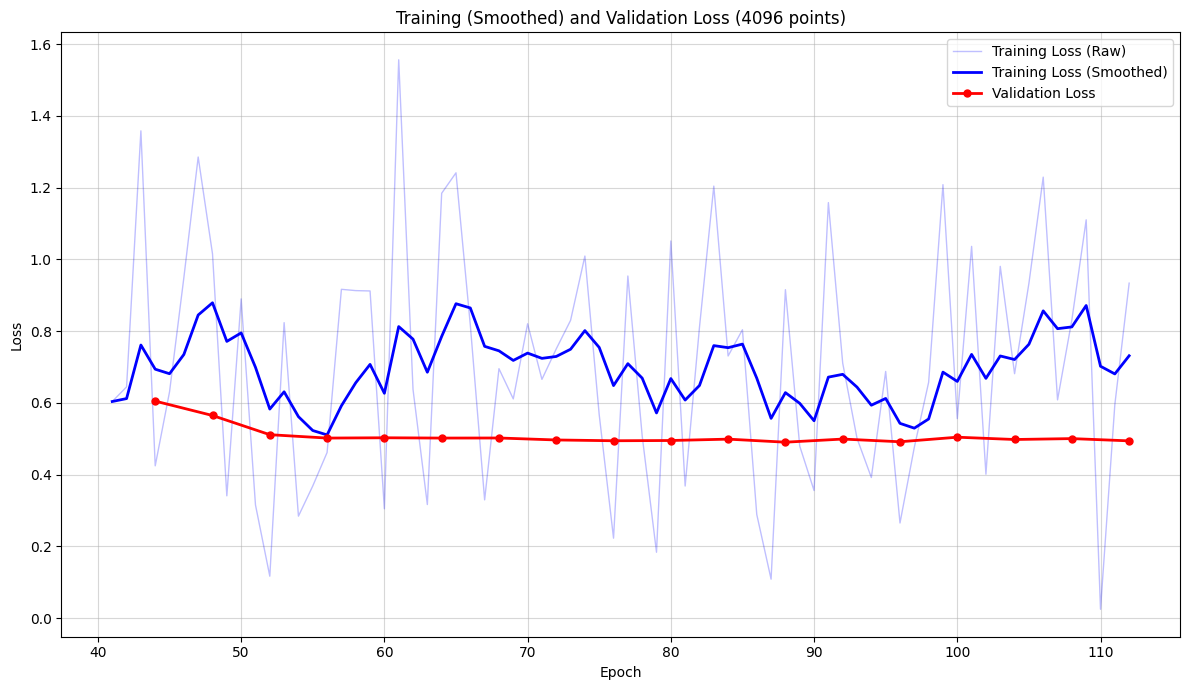

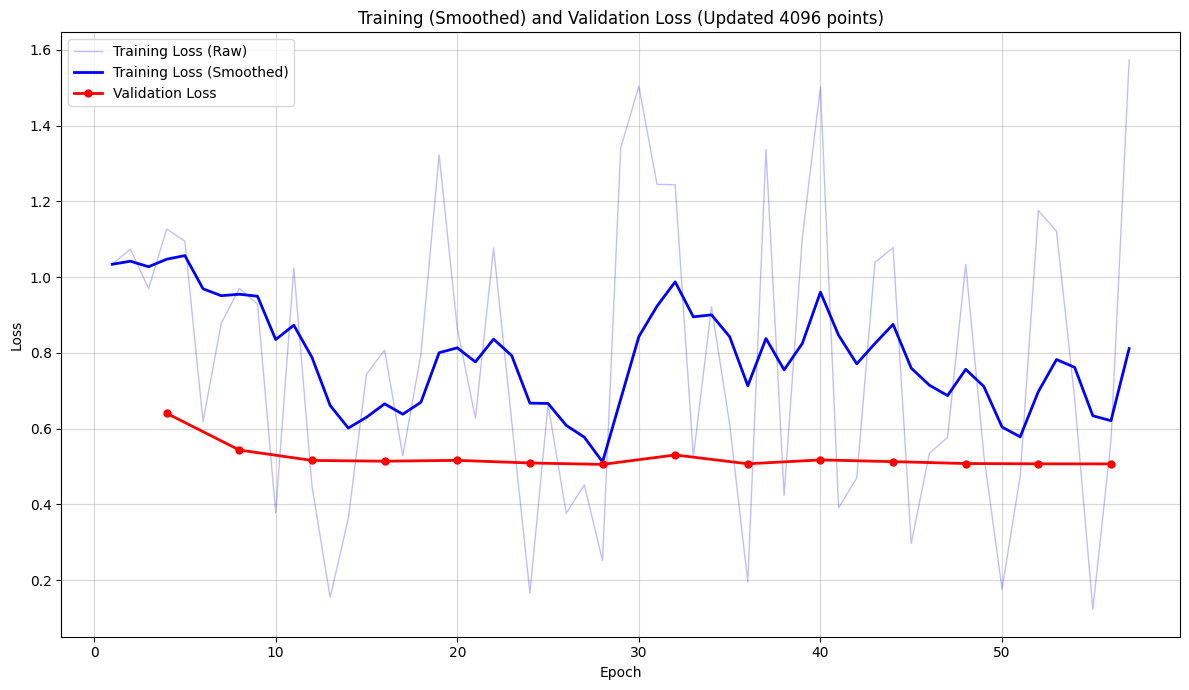

In [26]:
import re
import matplotlib.pyplot as plt
def parse(data):
    train_epochs = []
    train_losses = []
    valid_epochs = []
    valid_losses = []
    
    # 3. PARSE DATA
    # Matches: "Epoch 41 Metrics: ... loss =  6.036e-01"
    train_pattern = re.compile(r"Epoch (\d+) Metrics:.*loss =\s+([0-9\.eE\+\-]+)")
    # Matches: "Epoch 44 Metrics: Validation Loss =  6.047e-01"
    valid_pattern = re.compile(r"Epoch (\d+) Metrics: Validation Loss =\s+([0-9\.eE\+\-]+)")
    
    for line in data.split('\n'):
        if "[train]" in line:
            match = train_pattern.search(line)
            if match:
                train_epochs.append(int(match.group(1)))
                train_losses.append(float(match.group(2)))
        elif "[valid]" in line:
            match = valid_pattern.search(line)
            if match:
                valid_epochs.append(int(match.group(1)))
                valid_losses.append(float(match.group(2)))
        # 2. SMOOTHING FUNCTION (TensorBoard style)
        def smooth_curve(points, factor=0.75):
            smoothed_points = []
            for point in points:
                if smoothed_points:
                    previous = smoothed_points[-1]
                    smoothed_points.append(previous * factor + point * (1 - factor))
                else:
                    smoothed_points.append(point)
            return smoothed_points
    
        # Apply smoothing to training loss
        smooth_train_losses = smooth_curve(train_losses, factor=0.8)
    return train_epochs, train_losses, valid_epochs, valid_losses, smooth_train_losses



def visualize(te, tl, ve, vl, stl, title):
    plt.figure(figsize=(12, 7))
    
    # Plot Raw Training Loss (Faint)
    plt.plot(te, tl, label='Training Loss (Raw)', 
             color='blue', alpha=0.25, linewidth=1)
    
    # Plot Smoothed Training Loss (Solid)
    plt.plot(te, stl, label='Training Loss (Smoothed)', 
             color='blue', alpha=1.0, linewidth=2)
    
    # Plot Validation Loss
    if ve:
        plt.plot(ve, vl, label='Validation Loss', 
                 color='red', marker='o', linestyle='-', linewidth=2, markersize=5)
    
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(f'Training (Smoothed) and Validation Loss ({title} points)')
    plt.legend()
    plt.grid(True, which="both", ls="-", alpha=0.5)
    
    plt.tight_layout()
    plt.show()

te, tl, ve, vl, stl = parse(log_data_4096)
visualize(te, tl, ve, vl, stl, "4096")
te2, tl2, ve2, vl2, stl2 = parse(log_data_4096_v2)
visualize(te2, tl2, ve2, vl2, stl2, "Updated 4096")

#### Objective 1: NUNO can reach for the same data size the same prediction performance as FNO on uniform data 
- Create NUNO-compatible dataset with uniform sampling  
- Compare NUNO and FNO validation loss after 15000 steps on *uniform data* of same resolution (TODO)
- Profile both training runs and forward passes on validation datasets

Assumption: NUNO and FNO perform about the same from an accuracy standpoint with FNO having slightly better performance

#### Objective 2: NUNO is better than globally interpolating FNO on non-uniform data
- Implement global interpolation for FNO resulting in uniform grid 
- Compare NUNO and FNO (performance and accuracy) on Non-Uniform data

Assumption: NUNO largely outperforms FNO in irregular domains due to domain decomposition
Caveat: Current Random sampling logic might be too simple/uniform to test on (see Hypothesis 3)

### Hypothesis 3: NUNO is better than FNO for the use case of training on coarse meshes and predicting on fine 

#### Coarse Train -> Fine inference scales better with NUNO adaptive refinement
- Enhance current sampling logic (mostly script) by making it easily expandable with more samplers
- Add another sampler (e.g. Sparse Grids, adaptive refinement) and generate new Dataset
- Downsample grid resolution for uniform grid on FNO (e.g. 9x9 -> 3x3 (test both average and median))
- Inject for NUNO non-uniform data fidelity at center (e.g. 9x9 -> 3x3 within 3x3)
- Test forward for both 3x3 and 9x9 (due to flexibility of neural operator)

Expected Result: Dataset with higher KL-Divergence compared to pure random sampling

#### Objective 2: Test both NUNO and FNO (global interpolation) on new Dataset
- Profile training runs and forward passes
- Analyze validation losses
- Visualize results for both models  
Assumption: Both models will perform same as before in terms of speed. In terms of Valdiation loss, NUNO expected to remain the same or decrease error, for FNO a large increase is expected.

### Hypothesis 4: NUNO performance increases with different sampling logic (evaluate limits)

#### Objective 1: Create abstraction of sampler and implement XX sampling logic (see Austin et al. 2021) for new Dataset

### BONUS: NUNO can be applied to MHD (2D + 1) 


#### Objective 1: Create MHD Dataset (non-uniform)
- Use first random sampling for simplicity

#### Objective 2: Train NUNO on MHD
- Ensure time channels and subdomain channels can work simultaneously without problems in FNO
- Visualize results and analyze validation loss
Assumption: NUNO wil struggle to do both domain decomp. and time-based predictions due to channel limitations (bottleneck)

#### Objective 3 (optional): Test different sampling logic on MHD to compare results to 4.2